# Trabajo Práctico Nro. 3 - Diseño e implementación de filtros digitales FIR e IIR

Grupo 10, 2Q2026

Integrantes:

- Ana Negre
- Juan José Medina

In [2]:
pip install numpy matplotlib wget scipy control pandas schemdraw --quiet


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import os, ssl, warnings, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import signal
from scipy.io import loadmat
from IPython.display import display

plt.rcParams['figure.dpi'] = 100

def display(obj):
    if hasattr(obj, 'to_string'):
        print(obj.to_string(), end='\n\n')
    else:
        print(obj)

## Configuración y obtención de los datos

En primer lugar, se obtienen los archivos correspondientes al ECG y PCG utilizados en el anterior trabajo, de la misma forma que fue detallado en el mismo.

[Fuente: Pshysio.net](https://physionet.org/content/ephnogram/1.0.0/MAT/#files-panel)

In [4]:
import os

URL = "https://physionet.org/files/ephnogram/1.0.0/MAT/"
FILE = "ECGPCG0010.mat"  # from 00 to 69

target_dir = "./data/"
os.makedirs(target_dir, exist_ok=True)

filepath = os.path.join(target_dir, FILE)

if not os.path.exists(filepath):
  !wget --no-check-certificate -P {target_dir} {URL}{FILE}

In [5]:
from scipy.io import loadmat

data = loadmat(os.path.join(target_dir, FILE))
print(data.keys())
ecg = data['ECG'].flatten()
pcg = data['PCG'].flatten()
fs = int(data['fs'].flatten()[0])

print(f"ECG length: {len(ecg)}, sampling rate: {fs} Hz")
print(f"ECG duration: {len(ecg)/fs:.1f} seconds")
print(f"ECG samples: {len(ecg):.1f}")

print(f"PCG length: {len(pcg)}, sampling rate: {fs} Hz")
print(f"PCG duration: {len(pcg)/fs:.1f} seconds")
print(f"PCG samples: {len(pcg):.1f}")

dict_keys(['__header__', '__version__', '__globals__', 'ECG', 'PCG', 'fs'])
ECG length: 14400000, sampling rate: 8000 Hz
ECG duration: 1800.0 seconds
ECG samples: 14400000.0
PCG length: 14400000, sampling rate: 8000 Hz
PCG duration: 1800.0 seconds
PCG samples: 14400000.0


### Preprocesamiento de las señales
Para filtrar las señales según los filtros IIR y FIR se utilizan los hallazgos y conclusiones del trabajo práctico anterior.

En el caso del PCG y ECG, las mismas están a $f_s = 8\,\mathrm{kHz}$, pero su información útil está por debajo de 150 Hz (ECG) y 400 Hz (PCG). Luego como diseñar un pasa-alto de 0.5 Hz a 8 kHz exigiría demasiados coeficientes, se **submuestrea** con filtro antialiasing (con un $M$ que mantenga holgura sobre las bandas de interés) y los filtros se diseñan a la nueva frecuencia de muestreo. En particular, se utiliza $M=16$ para el ECG y $M=4$ para el PCG.

Adicionalmente, para evaluar qué tan bien se elimina la interferencia de las señales, se "contamina" las mismas utiliizando el sumador del trabajo práctico anterior. Para el ECG se utiliza la interferencia de red de 50 Hz (amplitud $0.15\,A$) en forma de senoidal y la deriva de línea base de 0.3 Hz (componentes de frecuencias bajas provenientes del movimiento/respiración del paciente, con amplitud $0.5\,A$). Para el PCG se utiliza el ruido blanco gaussiano ($\sigma = 0.05\,A$ y una interferencia de baja frecuencia de 10 Hz (amplitud $0.3\,A$) que justifica el pasa-alto.

Se utiliza como $A$ el máximo de la señal en cada caso.

In [6]:
def submuestreo(x, M):
    # decimate aplica un FIR antialiasing de fase cero antes de descartar muestras
    return signal.decimate(x, M, ftype='fir', zero_phase=True)

M_ecg, M_pcg = 16, 4
fs_e, fs_p = fs // M_ecg, fs // M_pcg            # 500 Hz y 2000 Hz

ecg_d = submuestreo(ecg, M_ecg); ecg_d = ecg_d - ecg_d.mean()
pcg_d = submuestreo(pcg, M_pcg); pcg_d = pcg_d - pcg_d.mean()
t_e = np.arange(len(ecg_d)) / fs_e
t_p = np.arange(len(pcg_d)) / fs_p

def senoidal(N, fs, f0, amp=1.0, fase=0.0):
    n = np.arange(N)
    return amp * np.cos(2 * np.pi * f0 * n / fs + fase)

def ruido_blanco(N, sigma=1.0, semilla=0):
    return np.random.default_rng(semilla).normal(0, sigma, N)

def sumador(*senales):
    return np.sum([np.asarray(x, dtype=float) for x in senales], axis=0)

# contaminación del ECG
A_e = np.max(np.abs(ecg_d))
red_50  = senoidal(len(ecg_d), fs_e, 50,  amp=0.15 * A_e)
deriva  = senoidal(len(ecg_d), fs_e, 0.3, amp=0.5 * A_e, fase=-np.pi / 2)   # arranca en 0
ecg_cont = sumador(ecg_d, red_50, deriva)

# contaminación del PCG
A_p = np.max(np.abs(pcg_d))
blanco = ruido_blanco(len(pcg_d), sigma=0.05 * A_p)
baja   = senoidal(len(pcg_d), fs_p, 10, amp=0.3 * A_p)
pcg_cont = sumador(pcg_d, blanco, baja)

dur = len(ecg_d) / fs_e
ZOOM = (dur / 2 - 2, dur / 2 + 2)

print(f"ECG: fs = {fs_e} Hz, {len(ecg_d)} muestras | PCG: fs = {fs_p} Hz, {len(pcg_d)} muestras | zoom = {ZOOM[0]:.1f}-{ZOOM[1]:.1f} s")

ECG: fs = 500 Hz, 900000 muestras | PCG: fs = 2000 Hz, 3600000 muestras | zoom = 898.0-902.0 s


(<Figure size 1200x440 with 2 Axes>,
 array([<Axes: title={'center': 'PCG: señal original vs contaminada'}>,
        <Axes: xlabel='t (s)'>], dtype=object))

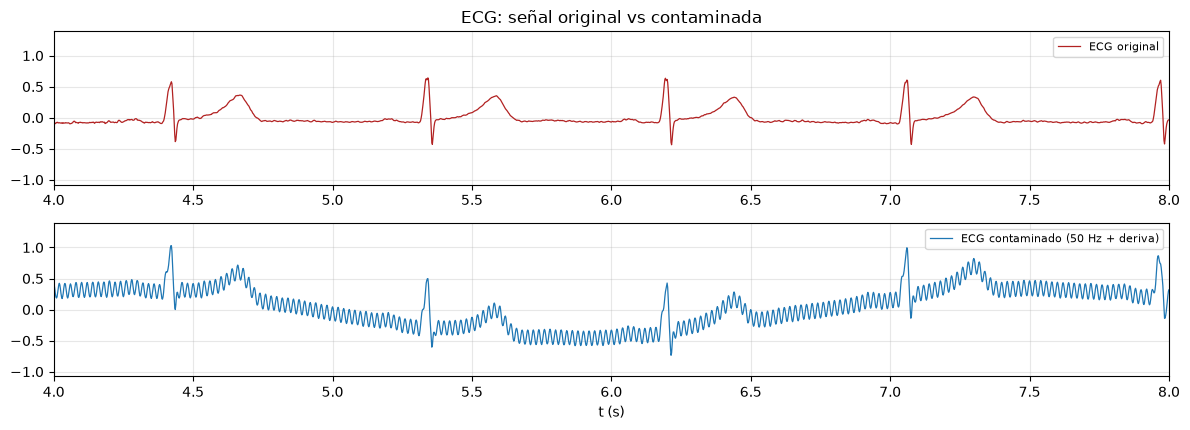

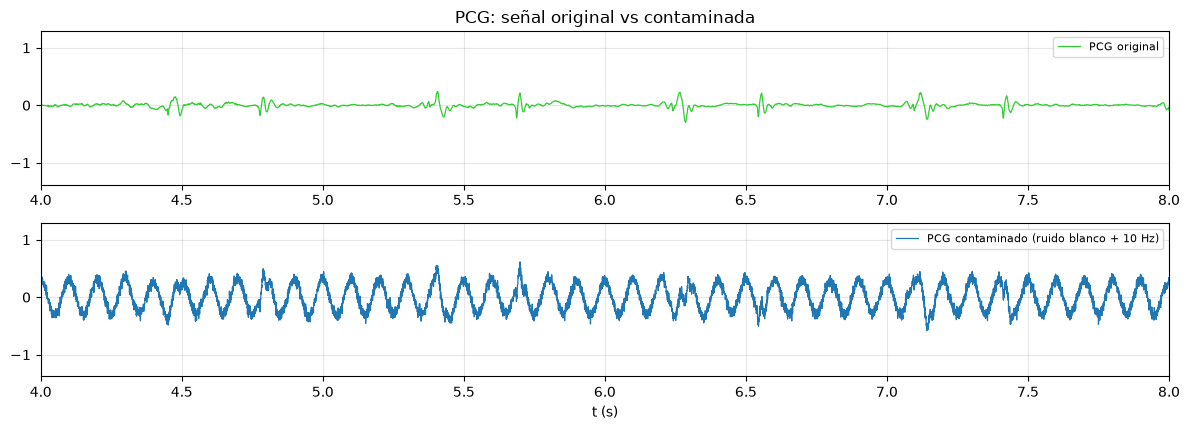

In [7]:
COLORES = ['C0', 'darkorange', 'C2', 'C3', 'C4']

def graficar_tiempo(t, curvas, titulo, zoom=None, ref=None):
    fig, axs = plt.subplots(len(curvas), 1, figsize=(12, 2.2 * len(curvas)), sharex=True, sharey=True)
    axs = np.atleast_1d(axs)
    for ax, (label, x, c) in zip(axs, curvas):
        if ref is not None:
            ax.plot(t, ref, color='0.6', lw=0.8, alpha=0.8, label='original (sin contaminar)')
        ax.plot(t, x, color=c, lw=0.9, label=label)
        ax.grid(True, alpha=0.3); ax.legend(loc='upper right', fontsize=8)
        ax.tick_params(labelbottom=True)
    axs[0].set_title(titulo); axs[-1].set_xlabel('t (s)')
    if zoom is not None:
        axs[-1].set_xlim(*zoom)
    plt.tight_layout()
    return fig, axs

def graficar_espectro(fs, curvas, titulo, fmax, fmin=0, log=False):
    # módulo de la DFT en dB
    fig, ax = plt.subplots(figsize=(12, 4.5))
    tope = -np.inf
    for label, x, c in curvas:
        w = np.hanning(len(x))
        X = np.fft.rfft(np.asarray(x, dtype=float) * w)
        f = np.fft.rfftfreq(len(x), 1 / fs)
        mag = 20 * np.log10(np.abs(X) / np.sum(w) + 1e-12)
        tope = max(tope, mag[(f >= max(fmin, 0.1)) & (f <= fmax)].max())
        ax.plot(f, mag, color=c, lw=0.8, label=label)
    ax.set_ylim(tope - 100, tope + 5)                      # 100 dB de rango, sin el piso numérico
    if log:
        ax.set_xscale('log'); fmin = max(fmin, 0.1)
    ax.set_xlim(fmin, fmax)
    ax.set_title(titulo); ax.set_xlabel('Frecuencia [Hz]'); ax.set_ylabel('|X(f)| [dB]')
    ax.grid(True, alpha=0.3, which='both'); ax.legend(loc='upper right', fontsize=8)
    plt.tight_layout()
    return fig, ax

## utilizamos potencia como metrica para ver ...
def potencia_banda(x, fs, f1, f2):
    f, P = signal.welch(x, fs, nperseg=min(len(x), 8 * fs))
    m = (f >= f1) & (f <= f2)
    return np.sum(P[m]) * (f[1] - f[0])

def tabla_metricas(ref, cont, salidas, fs, bandas, recorte_s=2):
    r = int(recorte_s * fs); sl = slice(r, len(ref) - r)
    P0 = {b: potencia_banda(cont, fs, *lim) for b, lim in bandas.items()}
    filas = {}
    for nombre, y in [('contaminada', cont)] + list(salidas.items()):
        fila = {f'ΔP {b} [dB]': 10 * np.log10(potencia_banda(y, fs, *lim) / P0[b]) for b, lim in bandas.items()}
        fila['SNR vs original [dB]'] = 10 * np.log10(np.var(ref[sl]) / np.var(y[sl] - ref[sl]))
        fila['correlación'] = np.corrcoef(ref[sl], y[sl])[0, 1]
        filas[nombre] = fila
    return pd.DataFrame(filas).T.round(2)

def tabla_lineal(componentes, filtros, fs, recorte_s):
    r = int(recorte_s * fs); sl = slice(r, -r)
    filas = {}
    for nombre, fn in filtros.items():
        fila = {}
        for comp, x in componentes.items():
            y = fn(x)
            if comp.startswith('señal'):
                fila[f'{comp}: SNR de distorsión [dB]'] = 10 * np.log10(np.var(x[sl]) / np.var(y[sl] - x[sl]))
            else:
                # piso en −150 dB: por debajo es cancelación exacta (cero sobre la frecuencia) y solo queda redondeo
                fila[f'{comp}: atenuación [dB]'] = max(10 * np.log10(np.var(y[sl]) / np.var(x[sl])), -150)
        filas[nombre] = fila
    return pd.DataFrame(filas).T.round(1)


def filtros_de(dis, nombres=None):
    out = {}
    for n, d in dis.items():
        if nombres is not None and n not in nombres:
            continue
        out[f'{n} | FIR'] = lambda x, d=d: signal.oaconvolve(x, d['b'], mode='same')
        out[f'{n} | IIR causal'] = lambda x, d=d: filtrar_iir(d['ba'], x)
    return out

graficar_tiempo(t_e, [('ECG original', ecg_d, 'firebrick'), ('ECG contaminado (50 Hz + deriva)', ecg_cont, 'C0')],
                'ECG: señal original vs contaminada', zoom=(4, 8))
graficar_tiempo(t_p, [('PCG original', pcg_d, 'limegreen'), ('PCG contaminado (ruido blanco + 10 Hz)', pcg_cont, 'C0')],
                'PCG: señal original vs contaminada', zoom=(4, 8))

(<Figure size 1200x450 with 1 Axes>,
 <Axes: title={'center': 'PCG: espectro antes de filtrar'}, xlabel='Frecuencia [Hz]', ylabel='|X(f)| [dB]'>)

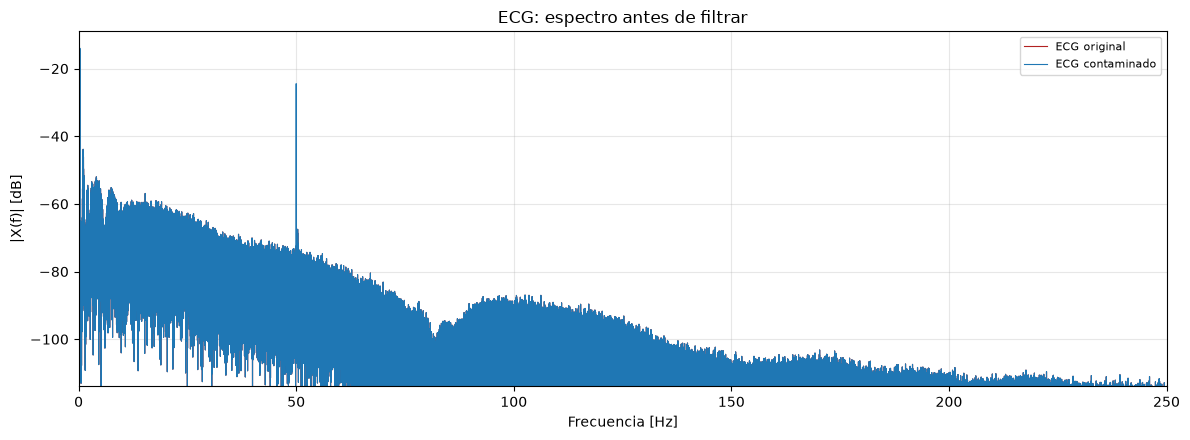

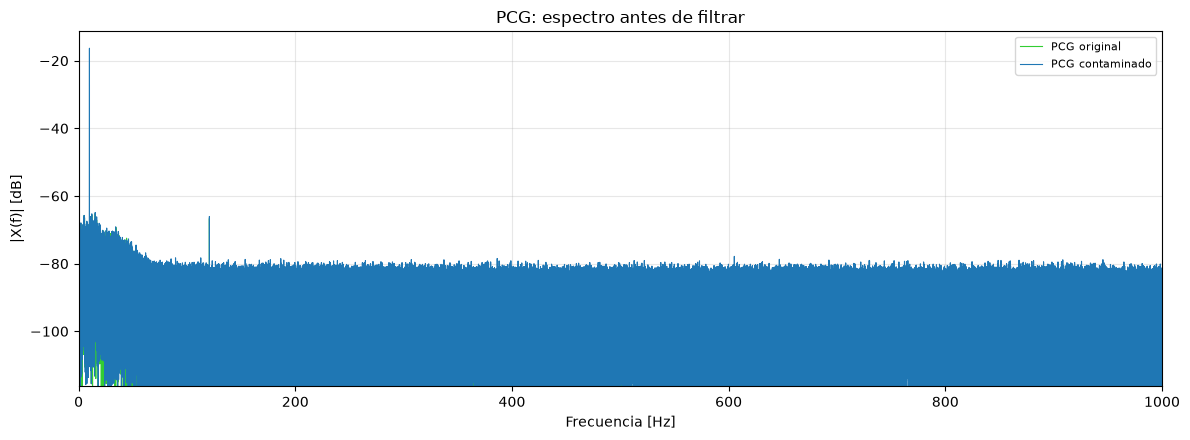

In [8]:
graficar_espectro(fs_e, [('ECG original', ecg_d, 'firebrick'), ('ECG contaminado', ecg_cont, 'C0')],
               'ECG: espectro antes de filtrar', fmax=fs_e / 2)
graficar_espectro(fs_p, [('PCG original', pcg_d, 'limegreen'), ('PCG contaminado', pcg_cont, 'C0')],
               'PCG: espectro antes de filtrar', fmax=fs_p / 2)

Vemos que en el ECG contaminado aparecen dos líneas que no están en el original: la **deriva de 0.3 Hz** (amplitud $0.5A$, la componente más grande por debajo de 1 Hz) y la **red de 50 Hz** ($0.15A$). Al ser senoidales puras, cada una ocupa un único bin. Fuera de esas líneas el espectro contaminado coincide con el original: como se vio en el TP2, el sumador no crea frecuencias nuevas. Esto ya anticipa las dificultades del diseño:

- La deriva está a menos de 1 Hz de la frecuencia cardíaca fundamental ($\sim 1Hz$1 Hz en el TP2). Para separarlas hace falta una transición de unas décimas de Hz, y en un FIR eso es caro, porque $L_h\propto f_s/\Delta f$.
- La red cae dentro de la banda del QRS (8–50 Hz). Hay dos estrategias: **recortar** la banda por encima de ~40 Hz (pasa-bajo o pasa-banda) o **quitar solo los 50 Hz** (notch).

En el PCG, el ruido blanco agrega un **piso plano** en todas las frecuencias. Por debajo de ~200 Hz, queda por debajo de la señal, y por encima de 400 Hz, donde el PCG casi no tiene contenido, el ruido domina. La **línea de 10 Hz** queda por debajo de la banda de máxima energía de S1 (25–45 Hz).

Dada las características de las señales contaminadas, resulta difícil observar componentes puntuales y su atenuación. Luego se propone utilizar la potencia por banda de las señales, dado que (por Parseval) sabemos que la energía en el tiempo equivale a la suma de la energía en cada banda de frecuencia.

Con esto puede verificarse cuánta "información" de la señal se conserva luego de su procesamiento. De esta forma, se podrá medir cuánto filtra cada filtro sin juzgarlo "a ojo". Además permite comparar la fraccion según frecuencia entre las señales originales y contaminadas:

In [9]:
# Fracción de la potencia de cada señal original por encima/debajo de los cortes
def fraccion(x, fs, f1, f2):
    return 100 * potencia_banda(x, fs, f1, f2) / potencia_banda(x, fs, 0, fs / 2)
print(f"ECG original: {fraccion(ecg_d, fs_e, 0, 0.5):.2f} % de la potencia < 0.5 Hz | "
      f"{fraccion(ecg_d, fs_e, 40, fs_e/2):.2f} % > 40 Hz | {fraccion(ecg_d, fs_e, 150, fs_e/2):.3f} % > 150 Hz")
print(f"PCG original: {fraccion(pcg_d, fs_p, 0, 25):.2f} % de la potencia < 25 Hz | "
      f"{fraccion(pcg_d, fs_p, 25, 45):.2f} % entre 25 y 45 Hz | {fraccion(pcg_d, fs_p, 400, fs_p/2):.3f} % > 400 Hz")

ECG original: 0.23 % de la potencia < 0.5 Hz | 1.94 % > 40 Hz | 0.003 % > 150 Hz
PCG original: 63.05 % de la potencia < 25 Hz | 26.43 % entre 25 y 45 Hz | 0.025 % > 400 Hz


## Diseño de filtros
Para procesar las señales se utilizarán dos familias de filtros: los **FIR** (finite impulse response) e **IIR** (infinite impulse response).

### FIR
En primer lugar, se tienen los filtros FIR. Los mismos tendrán una función de transferencia que puede expresarse como:
$$H(z)=\sum_{k=0}^{N-1} b[k]\,z^{-k}$$
Vemos que, al solo tener polos en el origen, la ROC de la transformada siempre contendrá la circunferencia unidad, y por ende estos filtros siempre serán estables.

En particular, para implementar estos filtros se utilizará el método del ventaneo. Se parte del filtro ideal pasabajo, donde:
$$\hat{H}(f)=\Pi(\frac{f}{2 f_c})$$
$$h_c(t)=2 f_c sinc(2 f_c t)$$
Este filtro analógico no es realizable, dado que $h_c$ es de duración infinita y no causal. Luego se muestrea $h_c$ con período T, se trunca a $L_h$ muestras y se lo desplaza $D=\frac{L_h - 1}{2}$. Para el truncado, se multiplica la respuesta al impulso por una ventana $w[n]$, lo cual cambiará las características del filtro según la ventana utilizada (rectangular, Hamming, Hann, Blackman, Kaiser). La ventana expresa un compromismo entre ancho de la transición (que tan "marcada" es la atenuación, y la cantidad de muestras que se necesitarán. Estas muestras tienen un efecto directo sobre la _fase_, dado que para un filtro tipo FIR el retardo de grupo es constante y es $\tau = \frac{L_h}{2}$.
El orden del filtro es $N= L_h - 1$.

### IIR
Por el otro lado, en el caso de los filtros IIR, la función de transferencia es un cociente de polinomios en $z^{-1}$:
$$H(z)=\frac{\sum_{k=0}^{M} b[k]\,z^{-k}}{1+\sum_{k=1}^{N} a[k]\,z^{-k}}=\frac{B(z)}{A(z)}\qquad\Longleftrightarrow\qquad y[n]=\sum_{k=0}^{M} b[k]\,x[n-k]-\sum_{k=1}^{N} a[k]\,y[n-k]$$

A diferencia de los FIR, tienen polos fuera del origen: la salida depende de entradas *y* de salidas pasadas, y la respuesta al impulso es de duración infinita. Luego a diferencia del FIR, la estabilidad no está garantizada y hay que verificarla en cada diseño, y el sistema del filtro solo será estable si todos sus polos están dentro del círculo unidad.

Luego para implementar estos filtros, se parte de un filtro analógico $H_a(s)=B(s)/A(s)$ y se convierte a uno digital $H(z)$. Sabemos que un sistema analógico causal es estable si y solo si todos sus polos cumplen $\mathrm{Re}\{s\}<0$. Se busca entonces una transformación $s\leftrightarrow z$ tal que:

1. el eje $i\omega$ del plano $s$ se corresponda con la circunferencia unidad del plano $z$ (relación directa entre las respuestas en frecuencia de ambos dominios);
2. el semiplano izquierdo del plano $s$ se mapee en el interior de la circunferencia unidad (un filtro estable se transforma en un filtro estable).

Para lograr esto se aproxima la integral con la regla del trapecio (transformación bilineal): si $w[n]$ aproxima a $y'(nT)$, entonces:
$$y[n]-y[n-1]=\frac{T}{2}\,\bigl(w[n-1]+w[n]\bigr)\quad\Rightarrow\quad H(z)=\frac{W(z)}{Y(z)}=\frac{2}{T}\,\frac{1-z^{-1}}{1+z^{-1}}$$

Como el derivador continuo es $H(s)=s$, resulta
$$s=\frac{2}{T}\,\frac{1-z^{-1}}{1+z^{-1}}=\frac{2}{T}\,\frac{z-1}{z+1}\qquad\Longleftrightarrow\qquad z=\frac{1+\frac{T}{2}s}{1-\frac{T}{2}s}\qquad H(z)=H_a(s)\Big|_{s=\frac{2}{T}\frac{z-1}{z+1}}$$

Con $s=\sigma+i\omega$ y $z=re^{i\Omega}$:
$$\sigma=\frac{2}{T}\,\frac{r^2-1}{r^2+2r\cos\Omega+1}\qquad\Rightarrow\qquad r<1\Leftrightarrow\sigma<0,\quad r=1\Leftrightarrow\sigma=0,\quad r>1\Leftrightarrow\sigma>0$$
ya que el denominador es $|z+1|^2>0$. Por lo tanto, el semiplano izquierdo se mapea en el interior de la circunferencia unidad (**estable $\Rightarrow$ estable**) y el eje imaginario en la circunferencia unidad.

Respecto a la relación entre frecuencias, vemos que sobre la circunferencia unidad, $z=e^{i\Omega}$ y $s=i\omega$:
$$i\omega=\frac{2}{T}\,\frac{e^{i\Omega}-1}{e^{i\Omega}+1}=i\,\frac{2}{T}\tan\!\left(\frac{\Omega}{2}\right)\qquad\Longleftrightarrow\qquad \omega=\frac{2}{T}\tan\!\left(\frac{\Omega}{2}\right),\quad \Omega=2\arctan\!\left(\frac{\omega T}{2}\right)$$
Luego todo el eje $0\le\omega<\infty$ se comprime en $0\le\Omega<\pi$, por lo que **no hay aliasing**, pero la relación es no lineal (se deforma la señal): solo para $\omega T\ll1$ vale $\Omega\approx\omega T$, y a frecuencias altas la respuesta se distorsiona sobre el eje de frecuencias.
Se conserva la forma por tramos de $|H_a|$ (las bandas planas siguen planas) pero se desplazan sus bordes. Por eso la bilineal es adecuada para filtros con respuesta constante por tramos (pasa-bajo, pasa-alto, pasa-banda, rechaza-banda), pero **no conserva la fase lineal** ni la forma de la respuesta al impulso.

Para que una frecuencia crítica (por ejemplo, la de corte) quede en su lugar luego de la transformación, el prototipo analógico se diseña en la frecuencia **predistorsionada** $\omega_a=\frac{2}{T}\tan\!\left(\frac{\Omega_c}{2}\right)$, con $\Omega_c=2\pi f_cT$:


### Filtros utilizados

Se aplican las bandas de corte provenientes del análisis del trabajo práctico anterior, provenientes de las distintas ondas relevantes de las señales (P, QRS, T, etc.).
Siguiendo el procedimiento de la teoría, cada filtro se especifica según los requerimientos: borde de la banda de paso $f_p$, borde de la banda de rechazo $f_{st}$, ripple máximo $r_p$ y atenuación mínima $\alpha_s$. De ahí salen la frecuencia de corte del prototipo ($f_c=\frac{f_p+f_{st}}{2}$), el largo $L_h$ del FIR y el orden $N$ del IIR.


| Señal | Filtro | $f_p$ [Hz] | $f_{st}$ [Hz] | $f_c$ [Hz] | Justificación (TP2)                                                                                                                       |
|---|---|---|---|---|-------------------------------------------------------------------------------------------------------------------------------------------|
| ECG | Pasa-bajo | 30 | 50 | 40 | Conserva P (5–30 Hz), T (0–10 Hz) y la mayor parte del QRS (centrado en 10 Hz). $f_{st}=50$ Hz deja la red justo en la banda de rechazo.  |
| ECG | Pasa-alto | 0.7 | 0.3 | 0.5 | La deriva (0.3 Hz) queda en la banda de rechazo; 0.7 Hz ≈ 42 lpm, por debajo de la frecuencia cardíaca, así que el ritmo pasa             |
| ECG | Pasa-banda | 0.7–30 | 0.3 / 50 | 0.5–40 | Combina los dos anteriores: saca la deriva y la red                                                                                       |
| ECG | Pasa-banda QRS | 8–12 | 2 / 18 | 5–15 | Banda del QRS (Pan y Tompkins, 1985), centrada en 10 Hz; útil para detectar picos R                                                       |
| ECG | Rechaza-banda (notch) | ≤47 y ≥53 | 49–51 | 48–52 | Saca la red (con ±1 Hz de tolerancia) sin recortar el ancho de banda del ECG                                                              |
| PCG | Pasa-bajo | 350 | 450 | 400 | Los soplos llegan hasta ~400 Hz; por encima domina el ruido                                                                               |
| PCG | Pasa-alto | 35 | 15 | 25 | La interferencia de 10 Hz queda en la banda de rechazo. Compromiso con S1 (máximo entre 25 y 45 Hz), que se cuantifica en 7.2             |
| PCG | Pasa-banda | 35–350 | 15 / 450 | 25–400 | Banda útil del PCG (S1, S2 y soplos)                                                                                                      |


Para los FIR se utiliza siempre simetría de $h[n]$ par y N impar (simetría tipo I). Los nombres de los filtros conservan la $f_c$ del prototipo. Para el FIR, $f_c$ es el punto de −6 dB; para el IIR, la plantilla fija $f_p$ y $f_{st}$, y su punto de −3 dB queda entre ambos.

Los parámetros comunes para ripple y atenuación mínima en la banda de rechazo, haciendo uso de la tabla provista en clase para el diseño de filtros FIR:
$$r_{máx}=0.1\qquad \alpha_s= 50dB$$
Con estos valores, según la tabla de la teoría, la ventana de menor lóbulo principal que cumple es **Hamming**: Hann llega solo a 43.9 dB.

In [10]:
RP, AS = 0.1, 50        # plantilla común: ripple máximo en la banda de paso y atenuación mínima en la de rechazo [dB]

# fp: borde(s) de la banda de paso, fst: borde(s) de la banda de rechazo [Hz]
espec_ecg = {
    'Pasa-bajo 40 Hz':        dict(btype='lowpass',  fp=30,        fst=50,        xlim=(0, 100),    log=False),
    'Pasa-alto 0.5 Hz':       dict(btype='highpass', fp=0.7,       fst=0.3,       xlim=(0.05, 20),  log=True),
    'Pasa-banda 0.5-40 Hz':   dict(btype='bandpass', fp=[0.7, 30], fst=[0.3, 50], xlim=(0.05, 250), log=True),
    'Pasa-banda QRS 5-15 Hz': dict(btype='bandpass', fp=[8, 12],   fst=[2, 18],   xlim=(0, 60),     log=False),
    'Notch 50 Hz':            dict(btype='bandstop', fp=[47, 53],  fst=[49, 51],  xlim=(30, 70),    log=False),
}

espec_pcg = {
    'Pasa-bajo 400 Hz':       dict(btype='lowpass',  fp=350,        fst=450,        xlim=(0, 1000), log=False),
    'Pasa-alto 25 Hz':        dict(btype='highpass', fp=35,         fst=15,         xlim=(1, 200),  log=True),
    'Pasa-banda 25-400 Hz':   dict(btype='bandpass', fp=[35, 350],  fst=[15, 450],  xlim=(1, 1000), log=True),
}

# Tabla de la teoría (método de ventanas)!! Muestras según ancho de transición, ripple, etc según tipo de ventana, etc.
TABLA_VENTANAS = pd.DataFrame(
    {'lóbulo principal': ['4π/Lh', '8π/Lh', '8π/Lh', '12π/Lh'],
     'lateral máx. [dB]': [-13.3, -31.5, -42.7, -58.1],
     'C': [1.84, 6.22, 6.64, 11.13],
     'αs [dB]': [20.9, 43.9, 54.5, 75.3],
     'rp [dB]': [1.57, 0.11, 0.033, 0.0030]},
    index=['boxcar', 'hann', 'hamming', 'blackman'])

def bandas(e):
    fp, fst = np.atleast_1d(e['fp']).astype(float), np.atleast_1d(e['fst']).astype(float)
    fc = (fp + fst) / 2                          # paso 2: Ωc = (Ωp + Ωs) / 2  (centro de la transición)
    Df = np.min(np.abs(fp - fst))                # pasa/rechaza-banda: se diseña con la transición más angosta
    return (fc[0] if fc.size == 1 else fc), Df

def elegir_ventana(As=AS, Rp=RP):
    # paso 3: la de lóbulo principal más angosto (menor C) que cumple αs y rp
    ok = TABLA_VENTANAS[(TABLA_VENTANAS['αs [dB]'] >= As) & (TABLA_VENTANAS['rp [dB]'] <= Rp)]
    return ok['C'].idxmin()

def largo_fir(Df, fs, C):
    # paso 4: Lh >= 1 + Cπ/ΔΩ con ΔΩ = 2π Δf / fs  =>  Lh >= 1 + C fs / (2 Δf); impar => tipo I
    Lh = int(np.ceil(1 + C * fs / (2 * Df)))
    return Lh + (1 - Lh % 2)

print(f"Plantilla: rp <= {RP} dB, αs >= {AS} dB  ->  ventana elegida: {elegir_ventana()}")
display(TABLA_VENTANAS)

Plantilla: rp <= 0.1 dB, αs >= 50 dB  ->  ventana elegida: hamming
         lóbulo principal  lateral máx. [dB]      C  αs [dB]  rp [dB]
boxcar              4π/Lh              -13.3   1.84     20.9    1.570
hann                8π/Lh              -31.5   6.22     43.9    0.110
hamming             8π/Lh              -42.7   6.64     54.5    0.033
blackman           12π/Lh              -58.1  11.13     75.3    0.003



A continuación se diseñan los filtros especificados, utilizando las frecuencias de muestreo $f_e$ y $f_p$ de las señales submuestreadas. Las especificaciones obtenidas se comparan con los parámetros teóricos.

In [11]:
def freqz_ba(ba, worN, fs):
    # H(z) = Π B_i(z)/A_i(z)
    H = 1
    for b, a in ba:
        f, Hi = signal.freqz(b, a, worN=worN, fs=fs)
        H = H * Hi
    return f, H

def filtrar_iir(ba, x):
    for b, a in ba:
        x = signal.lfilter(b, a, x)
    return x

def polos(ba):
    return np.concatenate([np.roots(a) for _, a in ba])

def ceros(ba):
    return np.concatenate([np.roots(b) for b, _ in ba])

def estable(ba, n=2**17):
    x = np.zeros(n); x[0] = 1
    with np.errstate(all='ignore'):
        h = np.abs(filtrar_iir(ba, x))
    return bool(np.all(np.isfinite(h)) and h[-n // 8:].max() < 1e-3 * h.max())

def cumple(ba, e, fs, Rp=RP, As=AS):
    rp, a_s = medir_plantilla(e, fs, ba=ba)
    return bool(rp <= Rp + 0.01 and a_s >= As - 0.5)

def mult_iir(ba):
    # forma directa: N+1 coeficientes b_k y N coeficientes a_k (a_0 = 1) por etapa
    return sum(len(b) + len(a) - 1 for b, a in ba)

# ---------- verificación de la plantilla (paso 6)
def medir_plantilla(e, fs, b=None, ba=None, n=2**16):
    # ripple en la banda de paso y atenuación mínima en la de rechazo, medidos sobre |H|
    f, H = signal.freqz(b, 1, worN=n, fs=fs) if ba is None else freqz_ba(ba, n, fs)
    m = 20 * np.log10(np.abs(H) + 1e-15)
    paso, rech = bandas_paso_rechazo(f, e)
    return m[paso].max() - m[paso].min(), -m[rech].max()

def bandas_paso_rechazo(f, e):
    fp, fst, bt = np.atleast_1d(e['fp']), np.atleast_1d(e['fst']), e['btype']
    if bt == 'lowpass':
        return f <= fp[0], f >= fst[0]
    if bt == 'highpass':
        return f >= fp[0], f <= fst[0]
    if bt == 'bandpass':
        return (f >= fp[0]) & (f <= fp[1]), (f <= fst[0]) | (f >= fst[1])
    return (f <= fp[0]) | (f >= fp[1]), (f >= fst[0]) & (f <= fst[1])

def disenar_fir(e, fs, Rp=RP, As=AS):
    fc, Df = bandas(e)
    ventana = elegir_ventana(As, Rp)
    Lh_teo = Lh = largo_fir(Df, fs, TABLA_VENTANAS.loc[ventana, 'C'])
    while True:
        # firwin calcula h[n] = sinc ideal retardada (Lh-1)/2 muestras × ventana (ver verificación más abajo)
        b = signal.firwin(Lh, fc, window=ventana, pass_zero=e['btype'], fs=fs)
        rp, a_s = medir_plantilla(e, fs, b=b)
        if (rp <= Rp and a_s >= As) or Lh > 5 * Lh_teo:
            break
        Lh += 2                                  # paso 6: si no cumple, se alarga (manteniéndolo impar)
    return dict(b=b, fc=fc, ventana=ventana, Lh_teo=Lh_teo, rp_fir=rp, As_fir=a_s)

def predistorsion(f, fs):
    return 2 * fs * np.tan(np.pi * np.asarray(f, dtype=float) / fs)

def bilineal(fp, fst, btype, fs, Rp, As, familia):
    wp, ws = predistorsion(fp, fs), predistorsion(fst, fs)
    if familia == 'butter':
        N, Wn = signal.buttord(wp, ws, Rp, As, analog=True)
        bs, as_ = signal.butter(N, Wn, btype, analog=True)
    elif familia == 'cheby1':
        N, Wn = signal.cheb1ord(wp, ws, Rp, As, analog=True)
        bs, as_ = signal.cheby1(N, Rp, Wn, btype, analog=True)
    else:
        N, Wn = signal.ellipord(wp, ws, Rp, As, analog=True)
        bs, as_ = signal.ellip(N, Rp, As, Wn, btype, analog=True)
    b, a = signal.bilinear(bs, as_, fs)
    return (b, a), N * (2 if btype in ('bandpass', 'bandstop') else 1)

def disenar_iir(e, fs, Rp=RP, As=AS, familia='ellip'):
    bt = e['btype']
    ba, orden = bilineal(e['fp'], e['fst'], bt, fs, Rp, As, familia)
    ba = [ba]
    if bt == 'bandpass':
        # alternativa: pasa-alto seguido de pasa-bajo, cada uno con su propio par (b, a) y la mitad del ripple.
        # Se usa si es más barata o si la forma directa B(z)/A(z) deja de ser estable o de cumplir la plantilla por redondeo.
        hp, Nh = bilineal(e['fp'][0], e['fst'][0], 'highpass', fs, Rp / 2, As, familia)
        lp, Nl = bilineal(e['fp'][1], e['fst'][1], 'lowpass', fs, Rp / 2, As, familia)
        directa_ok = estable(ba) and cumple(ba, e, fs, Rp, As)
        if Nh + Nl < orden or (not directa_ok and estable([hp, lp])):
            ba, orden = [hp, lp], Nh + Nl
    return ba, orden

# ---------- polos "exactos": el mismo diseño hecho con polos y ceros (zpk), sin pasar por los polinomios
def polos_exactos(e, fs, Rp=RP, As=AS, familia='butter'):
    wp, ws = predistorsion(e['fp'], fs), predistorsion(e['fst'], fs)
    if familia == 'butter':
        N, Wn = signal.buttord(wp, ws, Rp, As, analog=True)
        z, p, k = signal.butter(N, Wn, e['btype'], analog=True, output='zpk')
    else:
        N, Wn = signal.ellipord(wp, ws, Rp, As, analog=True)
        z, p, k = signal.ellip(N, Rp, As, Wn, e['btype'], analog=True, output='zpk')
    return signal.bilinear_zpk(z, p, k, fs)[1]

def disenar_todos(especificaciones, fs, familia='ellip'):
    dis = {}
    for nombre, e in especificaciones.items():
        ba, N = disenar_iir(e, fs, familia=familia)
        dis[nombre] = dict(e, **disenar_fir(e, fs), ba=ba, N=N)
    return dis

In [12]:
# Primer intento: IIR Butterworth en forma directa H(z) = B(z)/A(z)
x_prueba = ruido_blanco(60 * 2000)          # ruido de prueba, σ = 1

def prueba_ba(espec, fs, familia):
    filas = {}
    for nombre, e in espec.items():
        (b, a), N = bilineal(e['fp'], e['fst'], e['btype'], fs, RP, AS, familia)     # forma directa, sin cascada
        p_ba, p_ex = np.abs(np.roots(a)), np.abs(polos_exactos(e, fs, familia=familia))
        with np.errstate(all='ignore'):
            y = signal.lfilter(b, a, x_prueba[:int(60 * fs)])
        ymax, est = np.max(np.abs(y)), estable([(b, a)])
        rp, a_s = medir_plantilla(e, fs, ba=[(b, a)]) if est else (np.nan, np.nan)
        filas[nombre] = {'orden': N, 'max|a_k|': f"{np.max(np.abs(a)):.1e}",
                         '|p| máx exacto (zpk)': round(p_ex.max(), 6),
                         '|p| máx np.roots(a)': round(p_ba.max(), 6),
                         'h[n] decae (estable)': est,
                         'max|y| ruido σ=1, 60 s': 'inf / nan' if not np.isfinite(ymax) else f"{ymax:.2e}",
                         'rp [dB]': round(rp, 3), 'αs [dB]': round(a_s, 1),
                         'cumple plantilla': est and cumple([(b, a)], e, fs)}
    return pd.DataFrame(filas).T

print(f"Butterworth, rp = {RP} dB, αs = {AS} dB, forma directa B(z)/A(z)")
print(f"ECG (fs = {fs_e} Hz)"); display(prueba_ba(espec_ecg, fs_e, 'butter'))
print(f"PCG (fs = {fs_p} Hz)"); display(prueba_ba(espec_pcg, fs_p, 'butter'))

Butterworth, rp = 0.1 dB, αs = 50 dB, forma directa B(z)/A(z)
ECG (fs = 500 Hz)
                       orden max|a_k| |p| máx exacto (zpk) |p| máx np.roots(a) h[n] decae (estable) max|y| ruido σ=1, 60 s rp [dB] αs [dB] cumple plantilla
Pasa-bajo 40 Hz           15  8.3e+02             0.957708            0.957708                 True               1.30e+00     0.1    53.1             True
Pasa-alto 0.5 Hz          10  2.5e+02              0.99886            1.042767                False              inf / nan     NaN     NaN            False
Pasa-banda 0.5-40 Hz      28  6.0e+06             0.999164            1.468776                False              inf / nan     NaN     NaN            False
Pasa-banda QRS 5-15 Hz    14  2.9e+03              0.99454            1.059426                False              inf / nan     NaN     NaN            False
Notch 50 Hz               16  4.7e+03             0.994553            1.003797                 True               5.22e+00    1.44     0.4  

Vemos que el Butterworth necesita órdenes altos: 10 a 42. Es la familia más plana y por eso la de transición más lenta, y su orden lo fija el cociente $f_{st}/f_p$, porque cae $20N$ dB por década. En forma directa, con los coeficientes $b$ y $a$, el pasa alto y pasa banda, h[n] crece sin límite y el filtro se vuelve numéricamente inestable. Luego se elije cambiar de familia: se utilizará la familia elíptica de filtros, que con los mismos requerimienrtos requiere órdenes más bajos. 

In [13]:
print(f"Elíptico, misma plantilla, forma directa B(z)/A(z)")
print(f"ECG (fs = {fs_e} Hz)"); display(prueba_ba(espec_ecg, fs_e, 'ellip'))
print(f"PCG (fs = {fs_p} Hz)"); display(prueba_ba(espec_pcg, fs_p, 'ellip'))

Elíptico, misma plantilla, forma directa B(z)/A(z)
ECG (fs = 500 Hz)
                       orden max|a_k| |p| máx exacto (zpk) |p| máx np.roots(a) h[n] decae (estable) max|y| ruido σ=1, 60 s rp [dB] αs [dB] cumple plantilla
Pasa-bajo 40 Hz            5  7.2e+00             0.954765            0.954765                 True               1.27e+00     0.1    50.0             True
Pasa-alto 0.5 Hz           5  9.9e+00             0.999043            0.999043                 True               4.46e+00     0.1    50.0             True
Pasa-banda 0.5-40 Hz      10  1.7e+02             0.999077            1.000923                 True               1.50e+00   3.485    50.0            False
Pasa-banda QRS 5-15 Hz     8  6.6e+01             0.995436            0.995436                 True               5.68e-01     0.1    50.0             True
Notch 50 Hz                8  4.1e+01             0.993712            0.993712                 True               4.63e+00     0.1    50.0             

In [14]:
def resumen(dis, fs):
    filas = {}
    for n, d in dis.items():
        p = polos(d['ba'])
        rp_i, as_i = medir_plantilla(d, fs, ba=d['ba'])
        filas[n] = {'fp / fst [Hz]': f"{d['fp']} / {d['fst']}",
                    'fc FIR (-6 dB) [Hz]': d['fc'],
                    'FIR: Lh teoría': d['Lh_teo'], 'FIR: Lh final': len(d['b']),
                    'FIR: rp [dB]': round(d['rp_fir'], 3), 'FIR: αs [dB]': round(d['As_fir'], 1),
                    'FIR: retardo [ms]': 1000 * (len(d['b']) - 1) / 2 / fs,
                    'IIR: orden': d['N'], 'IIR: etapas (b, a)': len(d['ba']),
                    'IIR: rp [dB]': round(rp_i, 3), 'IIR: αs [dB]': round(as_i, 1),
                    'IIR: |polo| máx': round(np.max(np.abs(p)), 6),
                    'IIR estable': estable(d['ba']),
                    'mult/muestra FIR': len(d['b']), 'mult/muestra IIR': mult_iir(d['ba'])}
    return pd.DataFrame(filas).T

dis_ecg = disenar_todos(espec_ecg, fs_e)        # FIR Hamming + IIR elíptico (b, a)
dis_pcg = disenar_todos(espec_pcg, fs_p)

print(f"ECG (fs = {fs_e} Hz), ventana {dis_ecg['Pasa-bajo 40 Hz']['ventana']}, IIR elíptico"); display(resumen(dis_ecg, fs_e))
print(f"PCG (fs = {fs_p} Hz), ventana {dis_pcg['Pasa-bajo 400 Hz']['ventana']}, IIR elíptico"); display(resumen(dis_pcg, fs_p))

ECG (fs = 500 Hz), ventana hamming, IIR elíptico
                                fp / fst [Hz] fc FIR (-6 dB) [Hz] FIR: Lh teoría FIR: Lh final FIR: rp [dB] FIR: αs [dB] FIR: retardo [ms] IIR: orden IIR: etapas (b, a) IIR: rp [dB] IIR: αs [dB] IIR: |polo| máx IIR estable mult/muestra FIR mult/muestra IIR
Pasa-bajo 40 Hz                       30 / 50                40.0             85            85        0.038         52.9              84.0          5                  1          0.1         50.0        0.954765        True               85               11
Pasa-alto 0.5 Hz                    0.7 / 0.3                 0.5           4151          4151         0.03         52.8            4150.0          5                  1          0.1         50.0        0.999043        True             4151               11
Pasa-banda 0.5-40 Hz    [0.7, 30] / [0.3, 50]         [0.5, 40.0]           4151          4151         0.03         53.0            4150.0         11                  2        0.09

Finalmente vemos que todos los filtros cumplen la plantilla. Para los FIR $r_p$ está entre entre $0.03$ y $0.04 dB$ (la teoría da 0.033 dB para Hamming) y $\alpha_s$ entre $51$ y $53 dB$. Para IRI: $r_p\le 0.1$ dB y $\alpha_s\ge 50$ dB.

Se observa la diferencia de costo entre los dos tipos de filtro en los pasa-alto y pasa-banda de ECG: mientras que diseñando FIR se requieren **4151** coeficientes, con un retardo de **4.15 s**, el IIR equivalente es de orden 10 (25 multiplicaciones por muestra).
Por el otro lado, en el caso del IIR Butterworth, como el orden lo fija la relación $f_{st}/f_p$, como es la familia más plana, es también la transición más lenta. Para el pasabajo del ECG pide orden 15 y para el PCG pide orden 24. En los pasa-banda con bordes muy separados (ECG 0.5–40 Hz, PCG 25–400 Hz), la cascada sale mucho más barata que la transformación directa (orden 25 contra 58 en el ECG, 35 contra 82 en el PCG). En el QRS, de banda angosta, conviene la directa (14 contra 26).

Finalmente, vemos que todos los polos cumplen $|p|<1$, como garantiza la bilineal y la estructura de los FIR. Por ende todos estos filtros forman sistemas estables. Esto puede verse graficando los polos y ceros de estos filtros. Por ejemplo para el pasa-banda QRS, notch de 50Hz y pasa-bajo de 40Hz:

Pasa-bajo 40 Hz: ceros en f = [ 51.43  75.22 250.  ] Hz, |z| = 1.0..1.0; |polo| máx = 0.9548
Pasa-banda QRS 5-15 Hz: ceros en f = [ 3.37  5.81 16.51 28.26] Hz, |z| = 1.0..1.0; |polo| máx = 0.9954
Notch 50 Hz: ceros en f = [48.91 49.53 50.46 51.1 ] Hz, |z| = 1.0..1.0; |polo| máx = 0.9937


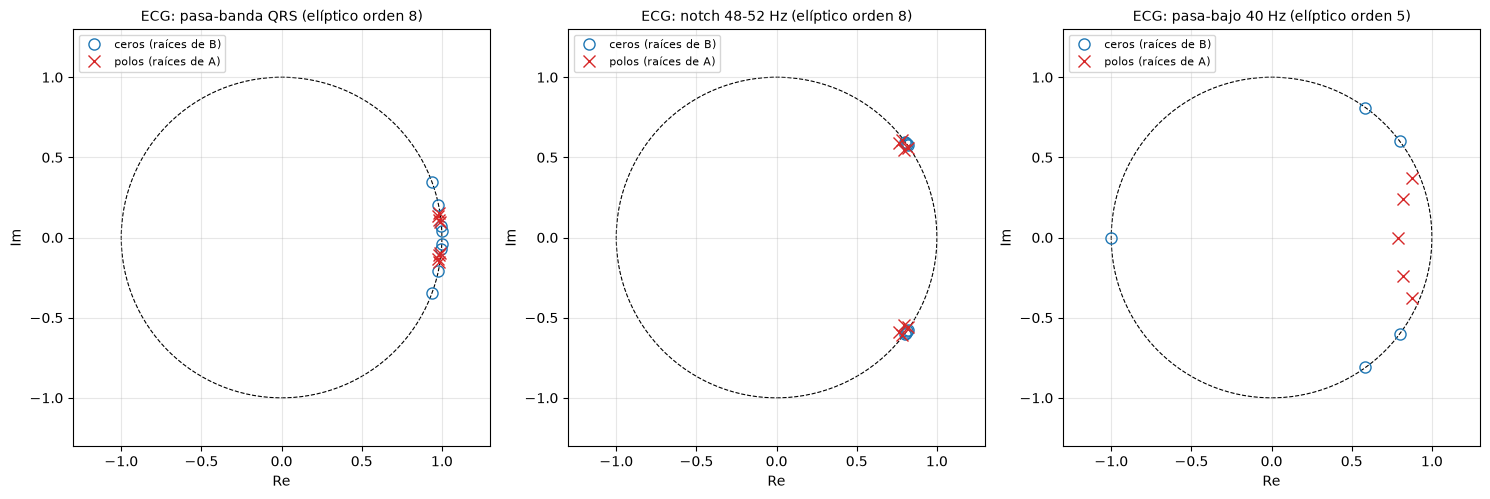

In [15]:
def plot_polos_ceros(ba, titulo, ax):
    z, p = ceros(ba), polos(ba)
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, ls='--', color='k', lw=0.8))
    ax.plot(z.real, z.imag, 'o', mfc='none', color='C0', ms=8, label='ceros (raíces de B)')
    ax.plot(p.real, p.imag, 'x', color='C3', ms=8, label='polos (raíces de A)')
    ax.set_aspect('equal'); ax.grid(True, alpha=0.3); ax.legend(loc='upper left', fontsize=8)
    ax.set_title(titulo, fontsize=10); ax.set_xlabel('Re'); ax.set_ylabel('Im')
    ax.set_xlim(-1.3, 1.3); ax.set_ylim(-1.3, 1.3)

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
plot_polos_ceros(dis_ecg['Pasa-banda QRS 5-15 Hz']['ba'], f"ECG: pasa-banda QRS (elíptico orden {dis_ecg['Pasa-banda QRS 5-15 Hz']['N']})", axs[0])
plot_polos_ceros(dis_ecg['Notch 50 Hz']['ba'], f"ECG: notch 48-52 Hz (elíptico orden {dis_ecg['Notch 50 Hz']['N']})", axs[1])
plot_polos_ceros(dis_ecg['Pasa-bajo 40 Hz']['ba'], f"ECG: pasa-bajo 40 Hz (elíptico orden {dis_ecg['Pasa-bajo 40 Hz']['N']})", axs[2])
plt.tight_layout()

# ángulos de los ceros sobre el círculo unidad, en Hz
for n in ['Pasa-bajo 40 Hz', 'Pasa-banda QRS 5-15 Hz', 'Notch 50 Hz']:
    z = ceros(dis_ecg[n]['ba']); p = polos(dis_ecg[n]['ba'])
    fz = np.sort(np.abs(np.angle(z[z.imag >= -1e-12]))) * fs_e / (2 * np.pi)
    print(f"{n}: ceros en f = {np.round(fz, 2)} Hz, |z| = {np.round(np.abs(z).min(), 6)}..{np.round(np.abs(z).max(), 6)}; "
          f"|polo| máx = {np.abs(p).max():.4f}")

Luego para verificar el comportamiento de estos filtros puede graficarse su respuesta en frecuencia para verificar que cumplan lo pedido, comparando así FIR e IIR para cada tipo.
 Las referencias son: punteada negra, −3 dB; gris, $f_c$; verde, $f_p$; roja, $f_{st}$ y la línea de −50 dB de la plantilla. El retardo de grupo se grafica solo donde $|H|>-40$ dB: en la banda de rechazo no tiene sentido físico y la derivada de la fase es ruido numérico. Para el FIR se usa el valor exacto $(L_h-1)/2$, que vale por la simetría.


In [16]:
def respuesta(coef, tipo, fs, n=2**15):
    if tipo == 'fir':
        w, h = signal.freqz(coef, 1, worN=n, fs=fs)
        gd = np.full(len(w), (len(coef) - 1) / 2)          # simétrico => τg = (Lh−1)/2 exacto (teoría)
    else:
        w, h = freqz_ba(coef, n, fs)                     # coef: lista de etapas (b, a)
        gd = -np.gradient(np.unwrap(np.angle(h)), 2 * np.pi * w / fs)   # τg = −dθ/dΩ [muestras]
    return w, h, np.unwrap(np.angle(h)), gd

def graficar_respuestas(curvas, fs, titulo, xlim=None, log=False, ylim=(-100, 5), fcs=None,
                        paneles=('mag', 'fase', 'gd'), n=2**15, plantilla=None):
    # curvas: lista de (etiqueta, 'fir'|'iir', coef)  ->  fir: vector b ; iir: lista de etapas (b, a)
    nombres = {'mag': 'Magnitud [dB]', 'fase': 'Fase [rad]', 'gd': 'Retardo de grupo [ms]'}
    fig, axs = plt.subplots(len(paneles), 1, figsize=(11, 3.2 * len(paneles)), sharex=True)
    axs = np.atleast_1d(axs)
    for label, tipo, coef in curvas:
        w, h, fase, gd = respuesta(coef, tipo, fs, n)
        mag = 20 * np.log10(np.abs(h) + 1e-12)
        datos = {'mag': mag, 'fase': fase, 'gd': np.where(mag > -40, 1000 * gd / fs, np.nan)}  # τg solo donde pasa señal
        for ax, p in zip(axs, paneles):
            ax.plot(w, datos[p], lw=1.1, label=label)
    for ax, p in zip(axs, paneles):
        ax.set_ylabel(nombres[p]); ax.grid(True, alpha=0.3, which='both')
        if p == 'mag':
            ax.set_ylim(*ylim); ax.axhline(-3, color='k', ls=':', lw=0.8)
            if plantilla is not None:
                ax.axhline(-AS, color='C3', ls=':', lw=1, label=f'requerimientos: −{AS} dB, fp (verde), fst (rojo)')
                for f_ in np.atleast_1d(plantilla['fp']):
                    ax.axvline(f_, color='C2', ls='-.', lw=0.9)
                for f_ in np.atleast_1d(plantilla['fst']):
                    ax.axvline(f_, color='C3', ls='-.', lw=0.9)
        if fcs is not None:
            for fc in np.atleast_1d(fcs):
                ax.axvline(fc, color='gray', ls='--', lw=0.8)
    axs[0].set_title(titulo); axs[0].legend(loc='lower right', fontsize=8)
    axs[-1].set_xlabel('Frecuencia [Hz]')
    if log:
        axs[-1].set_xscale('log')
    if xlim is not None:
        axs[-1].set_xlim(*xlim)
    plt.tight_layout()
    return fig, axs

def comparar_fir_iir(dis, fs, señal):
    for nombre, d in dis.items():
        curvas = [(f"FIR {d['ventana'].capitalize()} (Lh = {len(d['b'])})", 'fir', d['b']),
                  (f"IIR elíptico (orden {d['N']})", 'iir', d['ba'])]
        graficar_respuestas(curvas, fs, f"{señal}: {nombre} - FIR vs IIR", xlim=d['xlim'], log=d['log'],
                            fcs=d['fc'], plantilla=d)

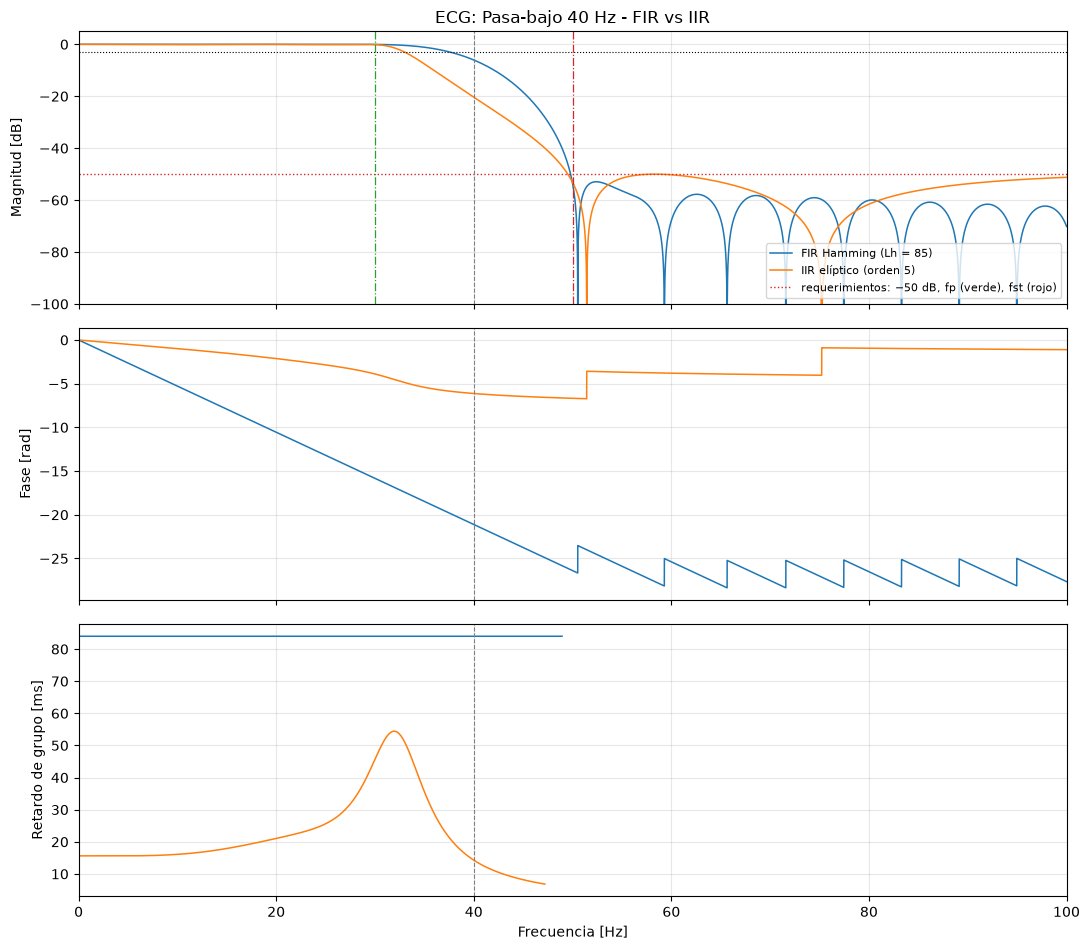

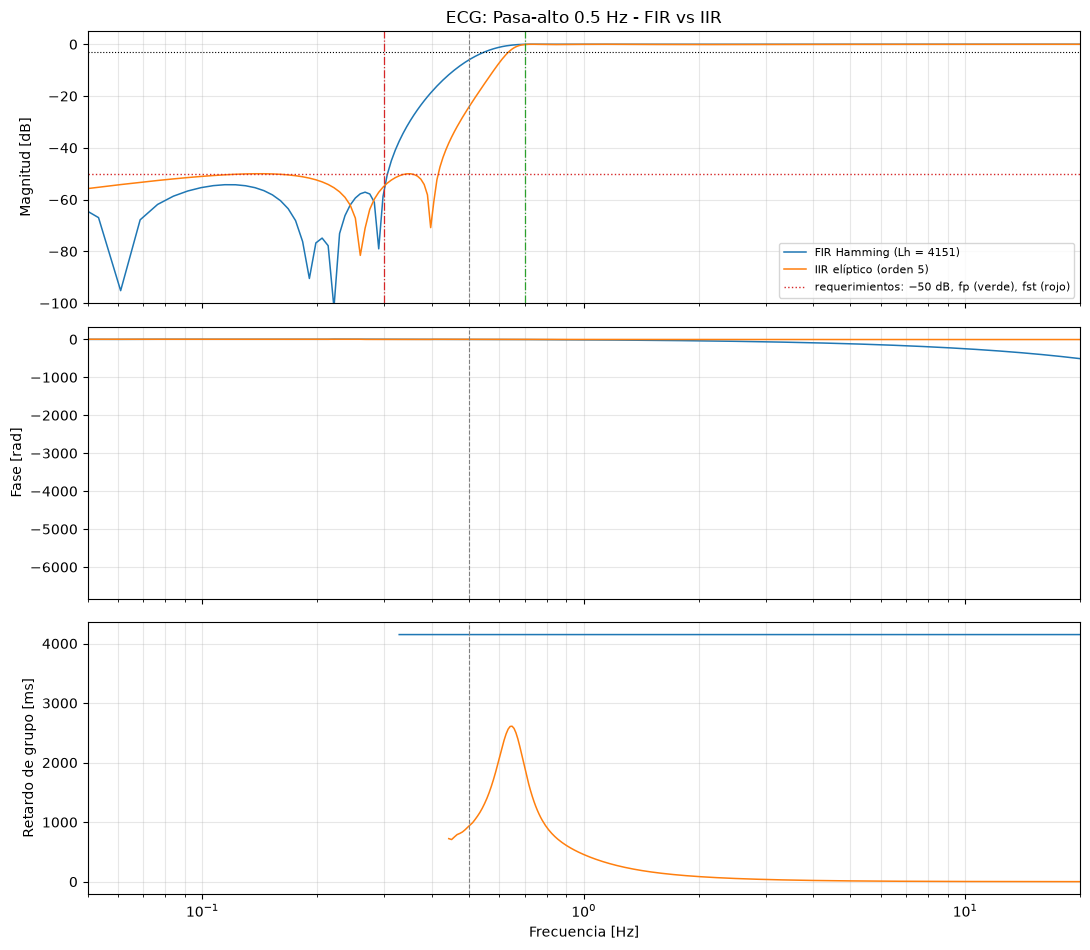

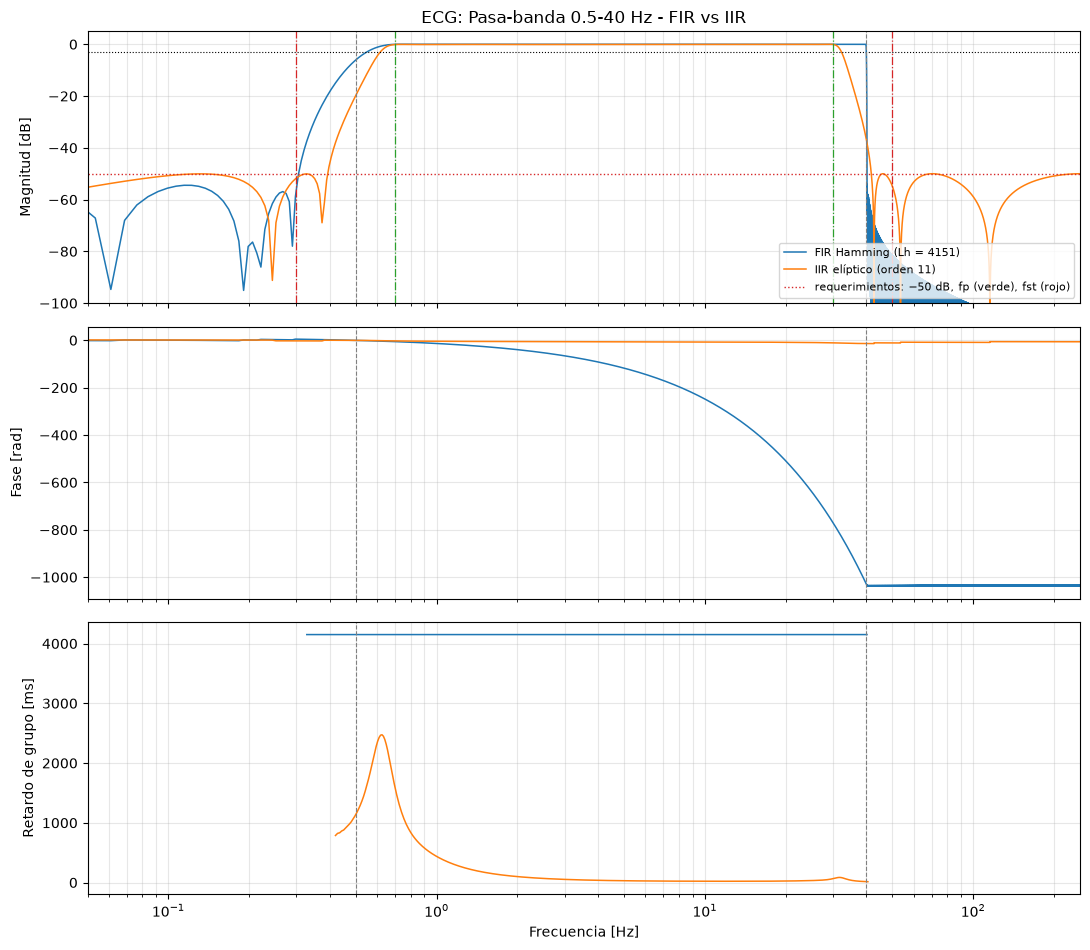

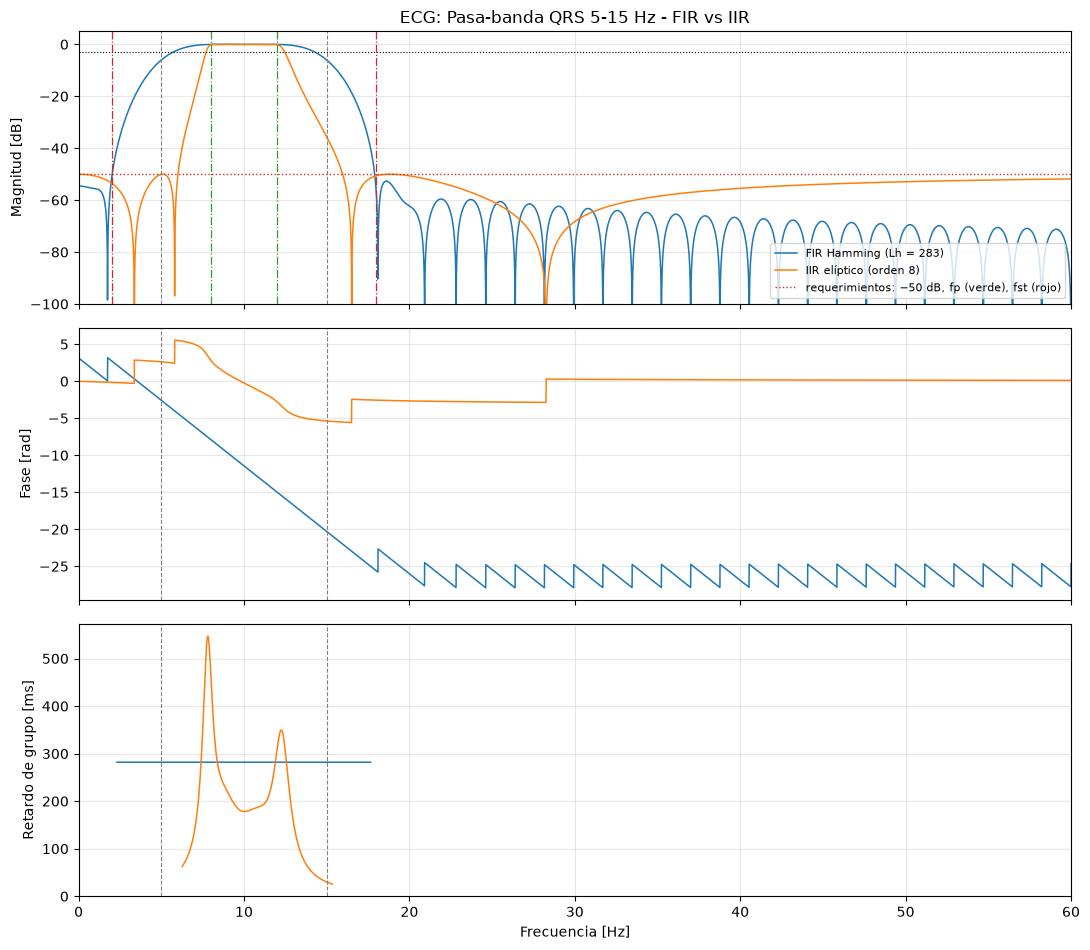

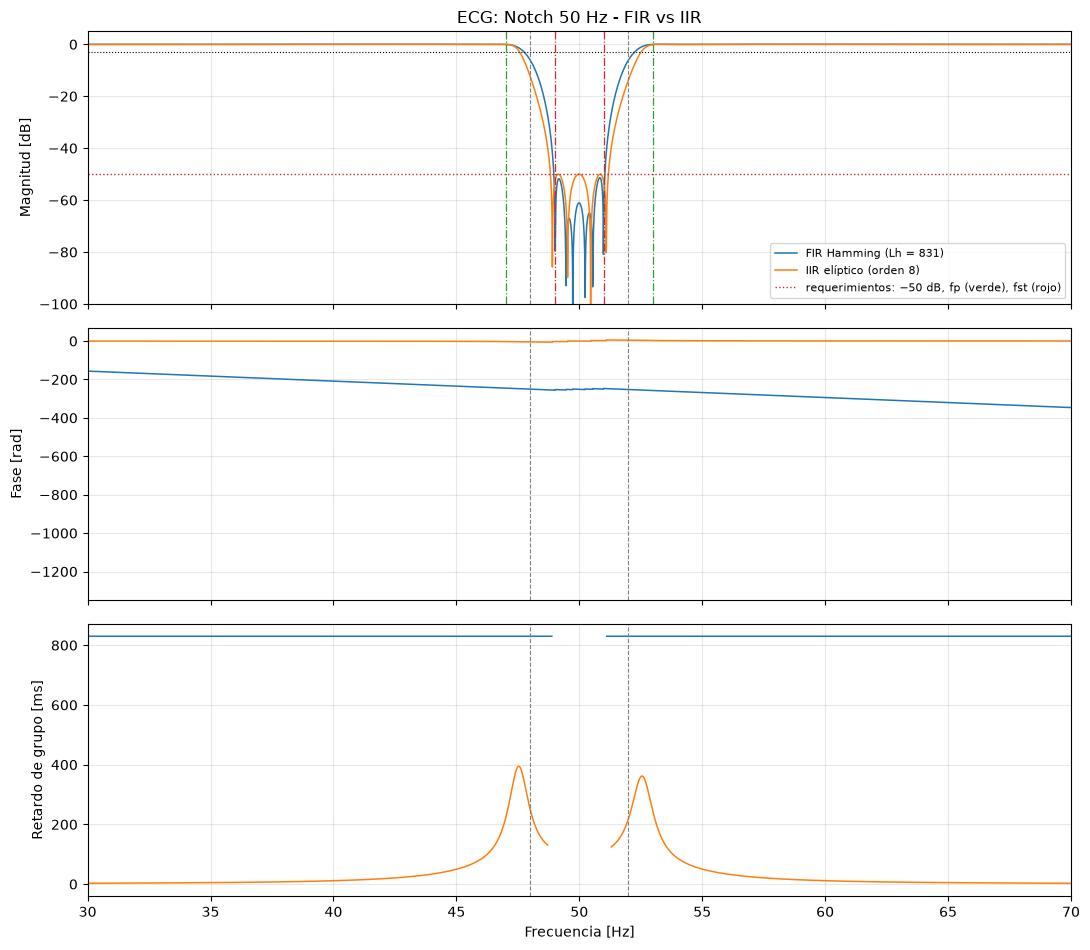

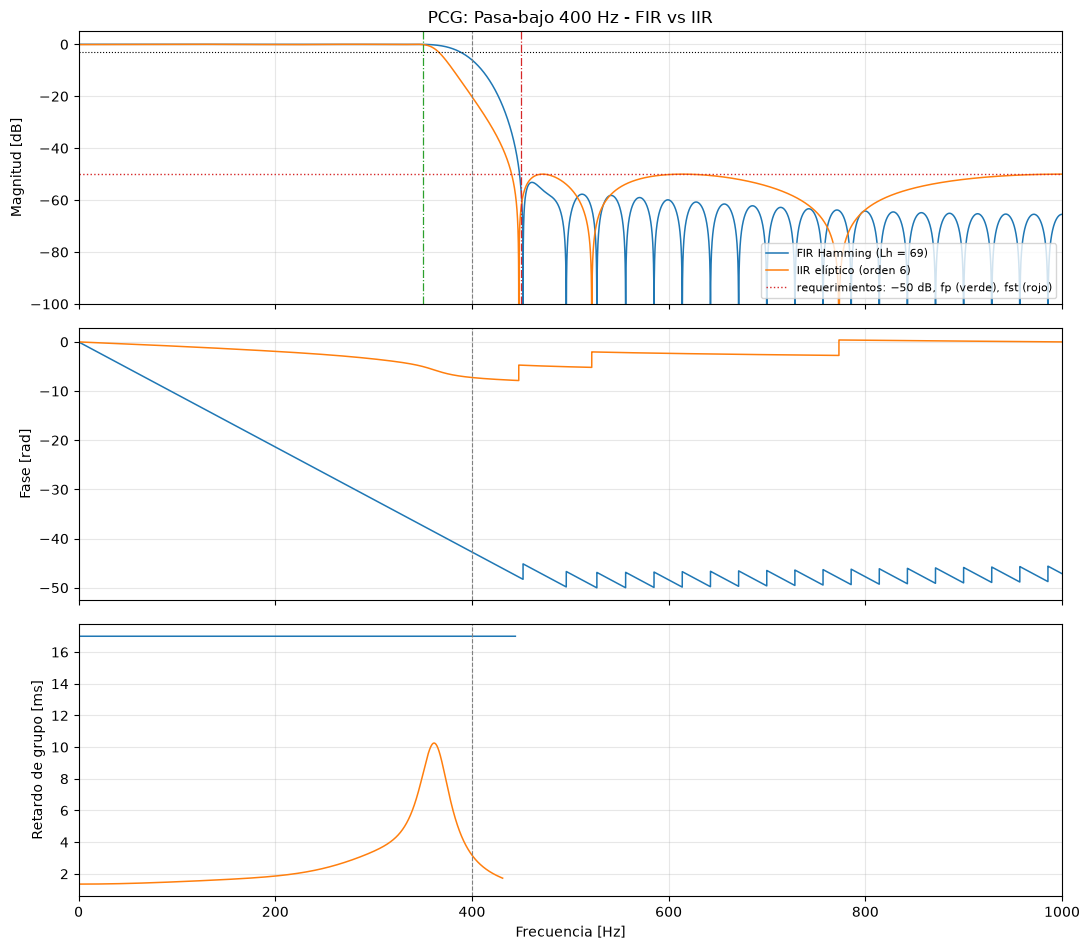

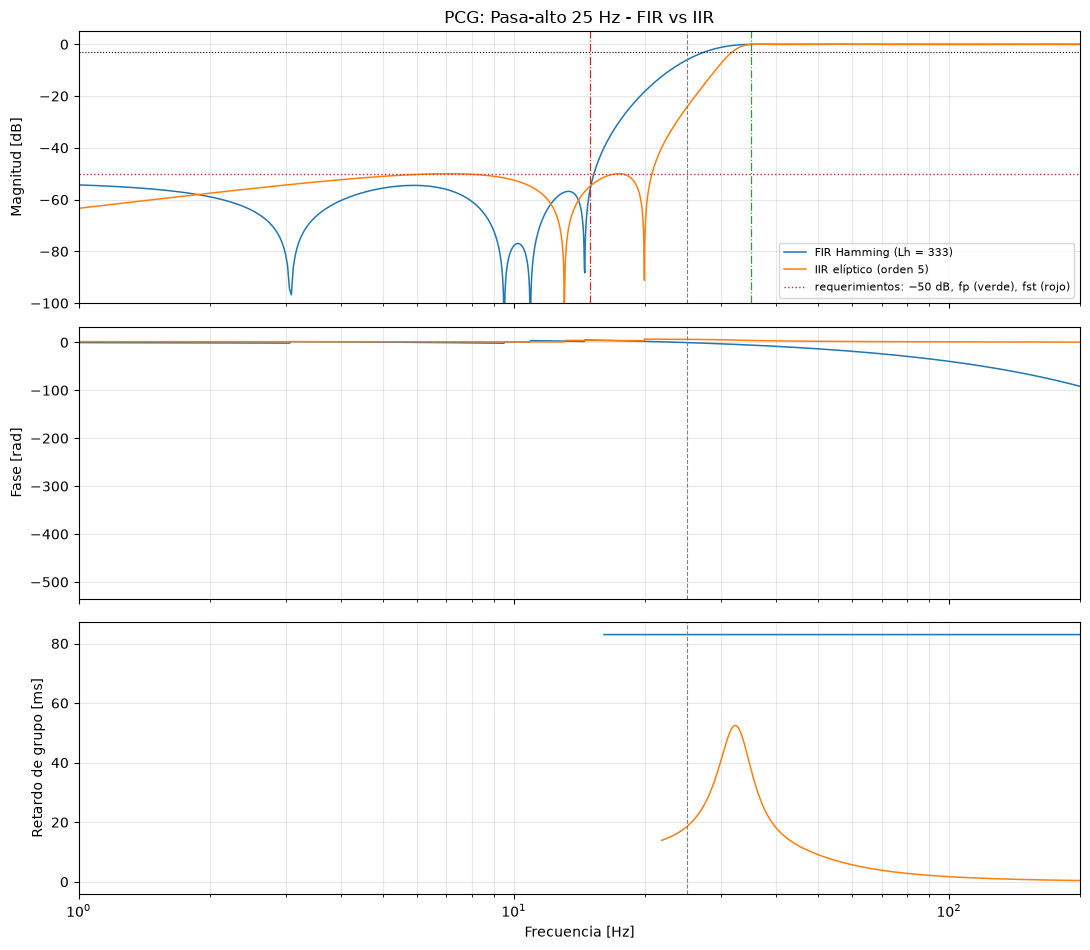

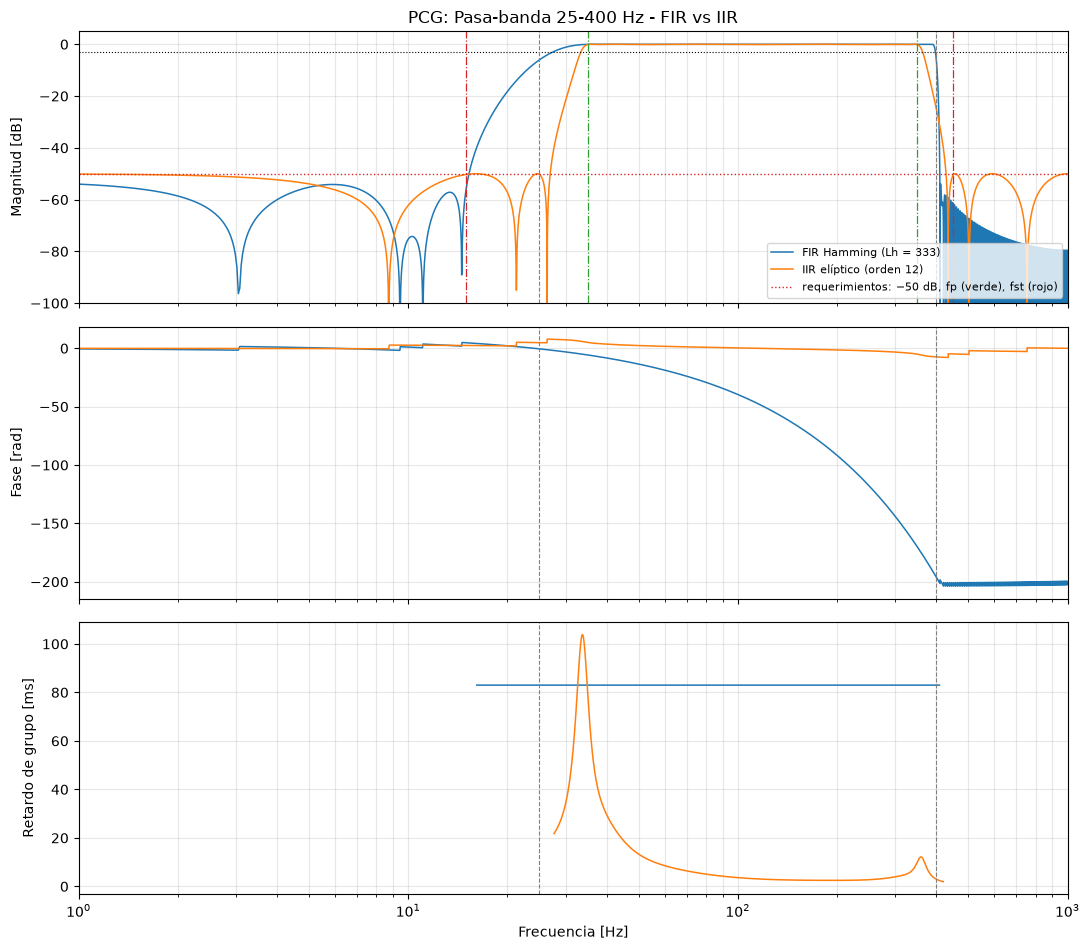

In [17]:
comparar_fir_iir(dis_ecg, fs_e, 'ECG')
comparar_fir_iir(dis_pcg, fs_p, 'PCG')

Luego, sobre cada filtro se mide:

- las frecuencias de −3 y −6 dB;
- el ancho de transición real (entre −0.1 y −50 dB), que se compara con la teoría, $\Delta f = C f_s/(2(L_h-1))$;
- el retardo de grupo;
- la duración del transitorio del IIR, es decir, el tiempo hasta que $|h[n]|$ queda por debajo del 0.1 % de su máximo.

Con estos valores se puede saber cuánto se recorta en cada extremo mediante las métricas de potencia en las bandas que se verán más adelante.

In [18]:
def cruce(f, mag, nivel, desde, hasta):
    # primera frecuencia, yendo de 'desde' (lado de paso) hacia 'hasta' (lado de rechazo), donde |H| cae bajo 'nivel'
    m = (f >= min(desde, hasta)) & (f <= max(desde, hasta))
    ff, mm = f[m], mag[m]
    if desde > hasta:
        ff, mm = ff[::-1], mm[::-1]
    i = int(np.argmax(mm < nivel))
    if i == 0 or mm[i] >= nivel:
        return np.nan
    return np.interp(nivel, [mm[i], mm[i - 1]], [ff[i], ff[i - 1]])

def transitorio(ba, fs, T=30):
    # tiempo hasta que la respuesta al impulso del IIR cae (y se queda) bajo el 0.1 % de su máximo
    x = np.zeros(int(T * fs)); x[0] = 1
    h = np.abs(filtrar_iir(ba, x))
    return np.nonzero(h > 1e-3 * h.max())[0][-1] / fs

def mediciones(dis, fs):
    filas = {}
    for nombre, d in dis.items():
        C = TABLA_VENTANAS.loc[d['ventana'], 'C']
        wF, hF, _, _ = respuesta(d['b'], 'fir', fs, 2**17)
        wI, hI, _, gdI = respuesta(d['ba'], 'iir', fs, 2**17)
        mF, mI = 20 * np.log10(np.abs(hF) + 1e-15), 20 * np.log10(np.abs(hI) + 1e-15)
        fps, fsts = np.atleast_1d(d['fp']), np.atleast_1d(d['fst'])
        paso = bandas_paso_rechazo(wI, d)[0]
        for k, (fp_, fst_) in enumerate(zip(fps, fsts)):
            ext = 0.5 * abs(fp_ - fst_)
            desde = np.clip(fp_ + np.sign(fp_ - fst_) * ext, 0, fs / 2)
            hasta = np.clip(fst_ - np.sign(fp_ - fst_) * ext, 0, fs / 2)
            filas[(nombre, f'borde {fp_}→{fst_} Hz')] = {
                'FIR f(−3 dB)': cruce(wF, mF, -3, desde, hasta),
                'FIR f(−6 dB)': cruce(wF, mF, -6, desde, hasta),
                'IIR f(−3 dB)': cruce(wI, mI, -3, desde, hasta),
                'FIR Δf medido (−0.1→−50 dB)': abs(cruce(wF, mF, -AS, desde, hasta) - cruce(wF, mF, -RP, desde, hasta)),
                'FIR Δf teoría C·fs/(2(Lh−1))': C * fs / (2 * (len(d['b']) - 1)),
                'IIR Δf medido (−0.1→−50 dB)': abs(cruce(wI, mI, -AS, desde, hasta) - cruce(wI, mI, -RP, desde, hasta)),
                'FIR τg [ms]': 1000 * (len(d['b']) - 1) / 2 / fs,
                'IIR τg mín/máx en paso [ms]': f"{1000 * np.nanmin(gdI[paso]) / fs:.1f} / {1000 * np.nanmax(gdI[paso]) / fs:.1f}",
                'IIR transitorio [s]': transitorio(d['ba'], fs)}
    return pd.DataFrame(filas).T.round(2)

print("ECG"); med_ecg = mediciones(dis_ecg, fs_e); display(med_ecg)
print("PCG"); med_pcg = mediciones(dis_pcg, fs_p); display(med_pcg)

# Recorte para las métricas: el mayor entre la mitad del FIR más largo y el transitorio del IIR más largo
RECORTE_E = np.ceil(max(max((len(d['b']) - 1) / 2 / fs_e for d in dis_ecg.values()), med_ecg['IIR transitorio [s]'].max()))
RECORTE_P = np.ceil(max(max((len(d['b']) - 1) / 2 / fs_p for d in dis_pcg.values()), med_pcg['IIR transitorio [s]'].max()))
print(f"Recorte para métricas: ECG {RECORTE_E:.0f} s, PCG {RECORTE_P:.0f} s por extremo")

ECG
                                          FIR f(−3 dB) FIR f(−6 dB) IIR f(−3 dB) FIR Δf medido (−0.1→−50 dB) FIR Δf teoría C·fs/(2(Lh−1)) IIR Δf medido (−0.1→−50 dB) FIR τg [ms] IIR τg mín/máx en paso [ms] IIR transitorio [s]
Pasa-bajo 40 Hz        borde 30→50 Hz        37.603851    39.975531    33.002855                   18.777017                    19.761905                   19.519007        84.0                 15.6 / 45.7               0.278
Pasa-alto 0.5 Hz       borde 0.7→0.3 Hz       0.548525     0.500148     0.634702                    0.370115                          0.4                    0.284744      4150.0                0.0 / 1878.8               1.274
Pasa-banda 0.5-40 Hz   borde 0.7→0.3 Hz       0.548508     0.500148      0.61617                    0.370019                          0.4                    0.307448      4150.0               21.4 / 1559.8               5.942
                       borde 30.0→50.0 Hz     39.95162    39.999736    32.283271            

#### Comparación entre tipos de filtro:
Al analizar los valores obtenidos anteriormente, vemos que:


- **Frecuencia de corte**: 
  
En el FIR, el punto de −6 dB cae exactamente en la $f_c$ de diseño, lo que confirma que $\Omega_c$ es el centro de la transición. El −3 dB del FIR queda ligeramente hacia adentro (37.6 Hz en el pasa-bajo, 0.549 Hz en el pasa-alto). En el Butterworth el −3 dB está más pegado a $f_p$: 33.9 Hz en el pasa-bajo, 0.58 Hz en el pasa-alto, 7.5/12.8 Hz en el QRS, 372.6 Hz y 29.0 Hz en los del PCG. Como los dos cumplen las especificaciones planteadas, "40 Hz" no significa lo mismo en uno y en otro: lo que se garantiza es $f_p$ y $f_{st}$.

- **Ripple y atenuación:** 

El FIR tiene ripple chico en la banda de paso (0.03–0.04 dB) y lóbulos en la de rechazo que se quedan alrededor de −53 dB: los lóbulos de Hamming decaen solo a −20 dB/década. El Butterworth es monótono: no tiene ripple, solo una caída de 0.1 dB en $f_p$, y su atenuación sigue creciendo después de $f_{st}$ (el pasa-bajo llega a −79 dB en 60 Hz, contra −58 dB del FIR).

- **Ancho de transición:** 

El medido en el FIR es un 5–8 % menor que el de la teoría. El IIR logra prácticamente el mismo ancho (18.9, 0.374 y 96 Hz) con **orden 15 contra orden 84**, orden 10 contra 4150, y orden 24 contra 68. En los pasa-banda del FIR, el borde de 40 Hz del ECG queda con una transición de **0.37 Hz**, mucho más angosta de lo pedido (sobrediseño impuesto por el borde de 0.5 Hz), y lo mismo pasa en el borde de 400 Hz del PCG (18.7 Hz). La cascada IIR, en cambio, le da a cada borde solo lo que necesita (19.3 y 92 Hz).

- **Fase:** 

En el FIR el retardo de grupo es una recta horizontal: 84 ms en el pasa-bajo, **4.15 s** en el pasa-alto y el pasa-banda del ECG, 282 ms en el QRS, 830 ms en el notch, y 17 y 83 ms en el PCG. En el IIR el retardo es menor en promedio pero **varía con la frecuencia** y crece hacia los bordes: 44→76 ms dentro de la banda de paso del pasa-bajo, hasta 1.8 s cerca de 0.7 Hz en el pasa-alto, 262→477 ms en el QRS, y de 0.2 ms lejos de 50 Hz a 300 ms en los bordes del notch. Componentes de distinta frecuencia (P y T de ~1–10 Hz, QRS de ~10–30 Hz) se retrasan distinto, y eso deforma la onda.

- **Transitorios:** 

En el IIR: 0.34 s en el pasa-bajo, 2.2 s en el pasa-alto de 0.5 Hz, **6.7 s** en el pasa-banda del ECG (lo dominan los polos de la sección pasa-alto, a 0.0011 del círculo unidad), 2.5 s en el QRS, 1.3 s en el notch y menos de 0.2 s en el PCG. En el FIR los primeros y últimos $(L_h-1)/2$ valores son convoluciones parciales: hasta 4.15 s en el ECG. Por eso las métricas recortan **7 s** por extremo en el ECG y **1 s** en el PCG.
  

- **Costo**:

En multiplicaciones por muestra: pasa-alto de 0.5 Hz, 4151 contra 25 (166 veces); notch, 831 contra 40; pasa-bajo de 40 Hz, 85 (43 aprovechando la simetría) contra 40; pasa-bajo del PCG, 69 (35) contra 60. 
Cuando la transición es ancha respecto de $f_s$, el FIR compite e incluso le gana al Butterworth, y cuando es angosta, el IIR gana por dos órdenes de magnitud.

Luego vemos que todos los tipos de filtro se pueden implementar tanto con FIR como con IIR, pero lo que cambia es el costo de cumplir la misma especificación.
Luego para ilustrar este costo, se calcula el largo del FIR, el orden del IIR para las tres familias (Butterworth, Chebyshev y elíptico), y las multiplicaciones por muestra. En el FIR son $L_h$, o $(L_h+1)/2$ si se aprovecha la simetría sumando primero $x[n-k]+x[n-L_h+1+k]$. En el IIR en forma directa son $2N+1$ por etapa: $N+1$ coeficientes $b_k$ y $N$ coeficientes $a_k$ ($a_0=1$).

In [19]:
def costos(espec, dis, fs):
    filas = {}
    for nombre, e in espec.items():
        d = dis[nombre]
        _, Df = bandas(e)
        nt_k = signal.kaiserord(AS, Df / (fs / 2))[0]; nt_k += 1 - nt_k % 2      # Kaiser: δp = δs = 10^(−As/20)
        ba_b, N_b = disenar_iir(e, fs, familia='butter')
        ba_c, N_c = disenar_iir(e, fs, familia='cheby1')
        filas[nombre] = {'Δf [Hz]': Df,
                         'FIR Hamming: Lh': len(d['b']), 'FIR Kaiser: Lh': nt_k,
                         'IIR Butterworth: orden': N_b, 'Butterworth (b, a) estable y cumple': estable(ba_b) and cumple(ba_b, e, fs),
                         'IIR Chebyshev I: orden': N_c, 'Chebyshev I (b, a) estable y cumple': estable(ba_c) and cumple(ba_c, e, fs),
                         'IIR elíptico: orden': d['N'],
                         'mult/muestra FIR Hamming': len(d['b']),
                         'mult/muestra FIR (aprovechando simetría)': (len(d['b']) + 1) // 2,
                         'mult/muestra Butterworth': mult_iir(ba_b),
                         'mult/muestra elíptico': mult_iir(d['ba'])}
    return pd.DataFrame(filas).T

print(f"Misma plantilla para todos (rp = {RP} dB, αs = {AS} dB)")
print(f"ECG, fs = {fs_e} Hz"); display(costos(espec_ecg, dis_ecg, fs_e))
print(f"PCG, fs = {fs_p} Hz"); display(costos(espec_pcg, dis_pcg, fs_p))

e_hp = espec_ecg['Pasa-alto 0.5 Hz']
ba_8k, N_8k = disenar_iir(e_hp, fs)
print(f"\nPasa-alto 0.5 Hz SIN submuestrear (fs = {fs} Hz): FIR Hamming Lh = {largo_fir(bandas(e_hp)[1], fs, TABLA_VENTANAS.loc['hamming', 'C'])} "
      f"| elíptico orden {N_8k}, |polo| máx exacto = {np.max(np.abs(polos_exactos(e_hp, fs, familia='ellip'))):.7f}, "
      f"estable en (b, a): {estable(ba_8k, n=2**20)}")

Misma plantilla para todos (rp = 0.1 dB, αs = 50 dB)
ECG, fs = 500 Hz


/Users/anegre/Documents/ITBA-docs/SeñalesYSistemas/TP1-SeñalesYSistemas-16.68/.venv/lib/python3.14/site-packages/scipy/signal/_filter_design.py:2469: BadCoefficients: Badly conditioned filter coefficients (numerator): the results may be meaningless
  return normalize(


                       Δf [Hz] FIR Hamming: Lh FIR Kaiser: Lh IIR Butterworth: orden Butterworth (b, a) estable y cumple IIR Chebyshev I: orden Chebyshev I (b, a) estable y cumple IIR elíptico: orden mult/muestra FIR Hamming mult/muestra FIR (aprovechando simetría) mult/muestra Butterworth mult/muestra elíptico
Pasa-bajo 40 Hz           20.0              85             75                     15                                True                      8                                True                   5                       85                                       43                       31                    11
Pasa-alto 0.5 Hz           0.4            4151           3663                     10                               False                      6                               False                   5                     4151                                     2076                       21                    11
Pasa-banda 0.5-40 Hz       0.4            4151           3663

## Aplicación de los filtros

Luego para cada filtro, se aplica a las señales correspondientes y se mide la densidad espectral de potencia antes y después del filtrado sobre la banda relevante. 
Las métricas se calculan recortando los transitorios medidos en 6.3 (6 s por extremo en el ECG y 1 s en el PCG):

- **ΔP [dB]:** cambio de potencia en cada banda respecto de la señal contaminada (negativo = atenuó). Se espera una caída grande en las bandas de ruido y ~0 dB en la banda útil.
- **SNR vs original [dB]** y **correlación:** qué tan parecida es la salida a la señal original. Es decir, se mide la relación señal ruido utilizando la potencia de las señales. 
- **Tabla lineal:** como $H\{x+r\}=H\{x\}+H\{r\}$, se filtra cada componente por separado. Así se mide exactamente la **atenuación de cada contaminación** y la **SNR de distorsión** de la señal ($\mathrm{var}(x)/\mathrm{var}(H\{x\}-x)$), sin que una se mezcle con la otra.

In [20]:
def filtrar_todos(x, dis):
    res = {}
    for nombre, d in dis.items():
        res[nombre] = {'FIR': signal.oaconvolve(x, d['b'], mode='same'),
                       'IIR': filtrar_iir(d['ba'], x)}           # lfilter(b, a, x)
    return res

res_ecg = filtrar_todos(ecg_cont, dis_ecg)
res_pcg = filtrar_todos(pcg_cont, dis_pcg)

comp_ecg = {'señal ECG': ecg_d, 'deriva 0.3 Hz': deriva, 'red 50 Hz': red_50}
comp_pcg = {'señal PCG': pcg_d, 'ruido blanco': blanco, 'interferencia 10 Hz': baja}
lin_ecg = tabla_lineal(comp_ecg, filtros_de(dis_ecg), fs_e, RECORTE_E)
lin_pcg = tabla_lineal(comp_pcg, filtros_de(dis_pcg), fs_p, RECORTE_P)
print("ECG: atenuación de cada contaminación y SNR de distorsión del ECG (filtrando cada componente por separado)")
display(lin_ecg)
print("PCG: ídem")
display(lin_pcg)

ECG: atenuación de cada contaminación y SNR de distorsión del ECG (filtrando cada componente por separado)
                                     señal ECG: SNR de distorsión [dB]  deriva 0.3 Hz: atenuación [dB]  red 50 Hz: atenuación [dB]
Pasa-bajo 40 Hz | FIR                                             17.8                            -0.0                       -53.6
Pasa-bajo 40 Hz | IIR causal                                       0.4                            -0.0                       -53.1
Pasa-alto 0.5 Hz | FIR                                            26.3                           -55.5                         0.0
Pasa-alto 0.5 Hz | IIR causal                                      0.3                           -54.6                        -0.0
Pasa-banda 0.5-40 Hz | FIR                                        16.6                           -55.5                       -81.7
Pasa-banda 0.5-40 Hz | IIR causal                                 -2.0                           -51.7     

### ECG

#### Pasa banda 0.5-40Hz 
Elimina a la vez la deriva (por debajo de 0.5 Hz) y la red de 50 Hz (por encima de 40 Hz). Se muestra un zoom de unos pocos latidos en el centro del registro, donde se ve la forma del QRS. 

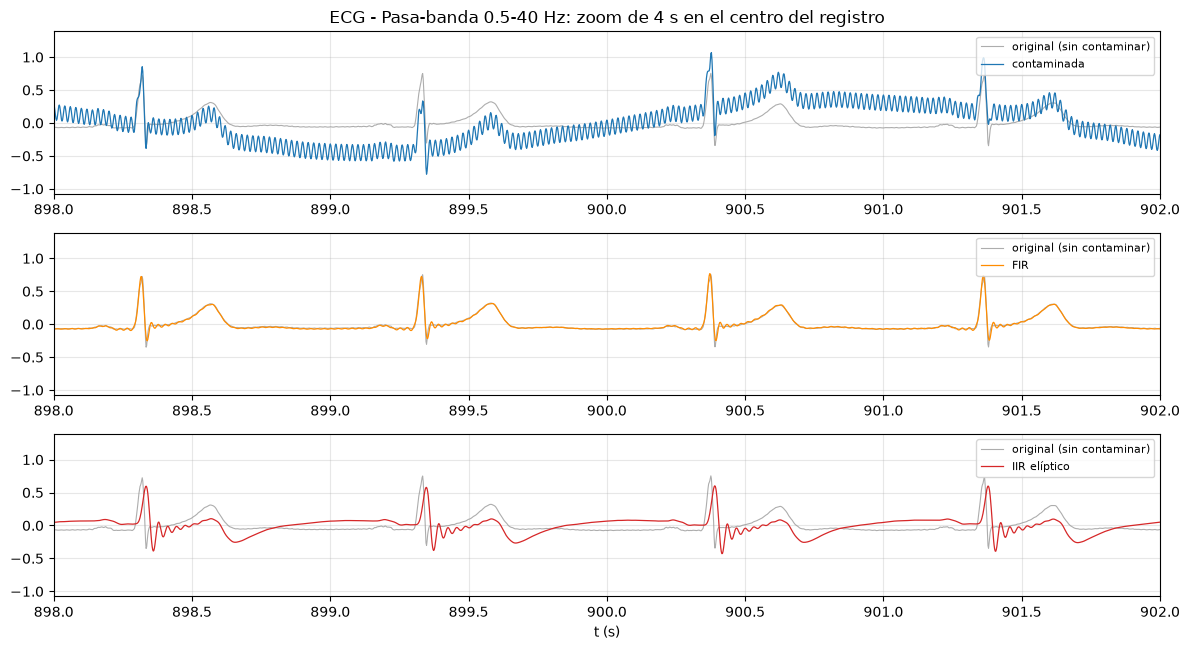

In [21]:
nombre = 'Pasa-banda 0.5-40 Hz'
y = res_ecg[nombre]
curvas = [('contaminada', ecg_cont, 'C0'), ('FIR', y['FIR'], 'darkorange'), ('IIR elíptico', y['IIR'], 'C3')]

graficar_tiempo(t_e, curvas, f'ECG - {nombre}: zoom de 4 s en el centro del registro', zoom=ZOOM, ref=ecg_d)
plt.show()

             ΔP deriva 0-0.5 Hz [dB]  ΔP útil 0.7-30 Hz [dB]  ΔP red 48-52 Hz [dB]  ΔP alta 60-250 Hz [dB]  SNR vs original [dB]  correlación
contaminada                     0.00                    0.00                  0.00                    0.00                 -7.19         0.40
FIR                           -42.53                   -0.00                -81.76                  -95.47                 16.64         0.99
IIR                           -42.81                   -0.04                -54.96                  -52.46                 -2.04         0.18

IIR: τg(10 Hz) = 21.8 ms, τg(1 Hz) = 436.9 ms | retardo que maximiza la correlación con el original: 18 ms


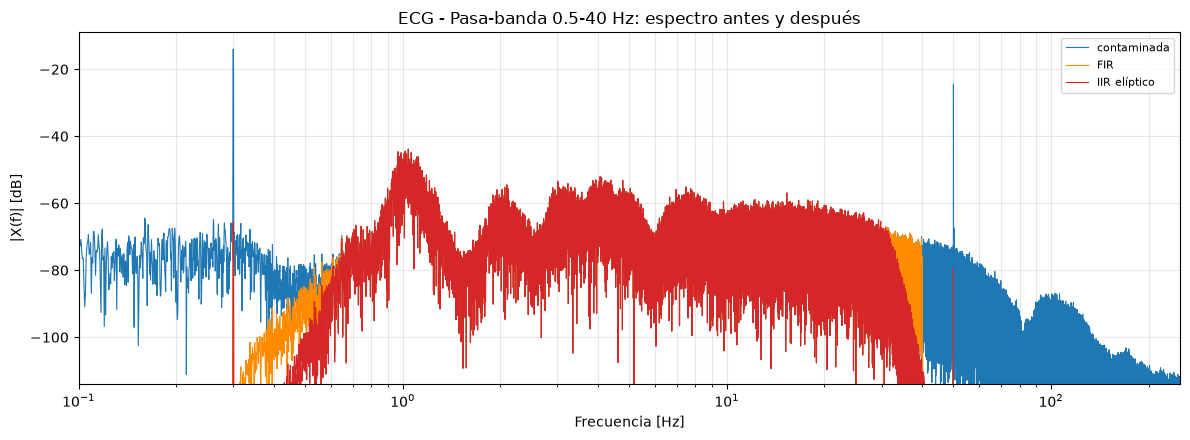

In [22]:
graficar_espectro(fs_e, [('contaminada', ecg_cont, 'C0'), ('FIR', y['FIR'], 'darkorange'), ('IIR elíptico', y['IIR'], 'C3')],
               f'ECG - {nombre}: espectro antes y después', fmax=fs_e / 2, fmin=0.1, log=True)

bandas_ecg = {'deriva 0-0.5 Hz': (0, 0.5), 'útil 0.7-30 Hz': (0.7, 30), 'red 48-52 Hz': (48, 52), 'alta 60-250 Hz': (60, 250)}
display(tabla_metricas(ecg_d, ecg_cont, y, fs_e, bandas_ecg, RECORTE_E))

# Retardo del IIR en la banda del QRS y desplazamiento del pico R (correlación cruzada con la original)
d = dis_ecg[nombre]
w_, h_, _, gd_ = respuesta(d['ba'], 'iir', fs_e, 2**15)
r = int(RECORTE_E * fs_e); sl = slice(r, -r)
lags = np.arange(-100, 101)
xc = [np.dot(ecg_d[sl], np.roll(y['IIR'], -k)[sl]) for k in lags]
print(f"IIR: τg(10 Hz) = {1000 * np.interp(10, w_, gd_) / fs_e:.1f} ms, τg(1 Hz) = {1000 * np.interp(1, w_, gd_) / fs_e:.1f} ms | "
      f"retardo que maximiza la correlación con el original: {1000 * lags[np.argmax(xc)] / fs_e:.0f} ms")

Vemos que se atenúan las frecuencias adecuadamente: la deriva baja 55.5 dB con el FIR y 51.7 dB con el IIR: de $0.5A$ queda del orden de $0.0015A$ o menos. La red baja 81.7 y 55 dB. 
En el gráfico de la señal completa, la oscilación lenta de la línea de base desaparece en las dos salidas, salvo en los primeros segundos del IIR (transitorio). 

- **Retardo de grupo:**

Luego como el FIR se compensa según el $\tau$ (conocido pues es una constante), la salida queda alineada gracias a la fase lineal.  

- **Forma y amplitud del QRS:** 

El FIR (retardo compensado) queda **alineado** con el original gracias a su fase lineal. Lo único que pierde es el contenido entre ~30 y 40 Hz y lo que está por encima, que en el ECG es poco (ver el porcentaje de potencia por encima de 40 Hz impreso en la sección 3) y se nota a lo sumo en un pico R levemente más redondeado. 

El IIR, por el otro lado, está **retrasado**: su retardo de grupo es de ~22 ms en 10 Hz (QRS) pero de ~0.44 s en 1 Hz. Como las ondas lentas (P, T, línea de base) se retrasan mucho más que el QRS, la relación temporal entre ondas se deforma. 

- **Transitorio inicial:** 

En el IIR dura ~**5.9 s**, mucho más que en el resto, porque los polos de la etapa pasa-alto están a 0.001 del círculo unidad y su contribución decae como $|p|^n$, es decir, muy lentamente. El FIR solo tiene efecto de borde en los primeros y últimos 4.15 s (convolución parcial).


Finalmente, vemos que el FIR conserva mejor la morfología: el IIR queda último por el retardo, no porque elimine peor las interferencias. Si se corre su salida 18 ms, el QRS se superpone con el original, pero la P y la T siguen desplazadas, porque el retardo no es el mismo para todas las frecuencias. 
El IIR es la opción para tiempo real con poco costo (24 multiplicaciones por muestra contra 4151) si se acepta esa distorsión de fase.


#### Pasa-bajo, pasa-alto, QRS y notch
Se repite el análisis con los demás filtros para ver qué hace cada uno por separado (FIR comparado con IIR). En el notch se ve que la red desaparece **sin recortar** la banda de 40 a 250 Hz del ECG, a diferencia del pasa-banda.

Pasa-bajo 40 Hz
             ΔP deriva 0-0.5 Hz [dB]  ΔP útil 0.7-30 Hz [dB]  ΔP red 48-52 Hz [dB]  ΔP alta 60-250 Hz [dB]  SNR vs original [dB]  correlación
contaminada                      0.0                    0.00                  0.00                    0.00                 -7.19         0.40
FIR                             -0.0                   -0.01                -53.01                  -61.97                 -6.83         0.41
IIR                             -0.0                   -0.04                -53.09                  -52.22                 -7.58         0.22

Pasa-alto 0.5 Hz
             ΔP deriva 0-0.5 Hz [dB]  ΔP útil 0.7-30 Hz [dB]  ΔP red 48-52 Hz [dB]  ΔP alta 60-250 Hz [dB]  SNR vs original [dB]  correlación
contaminada                     0.00                    0.00                   0.0                     0.0                 -7.19         0.40
FIR                           -42.53                   -0.00                   0.0                    -0.0        

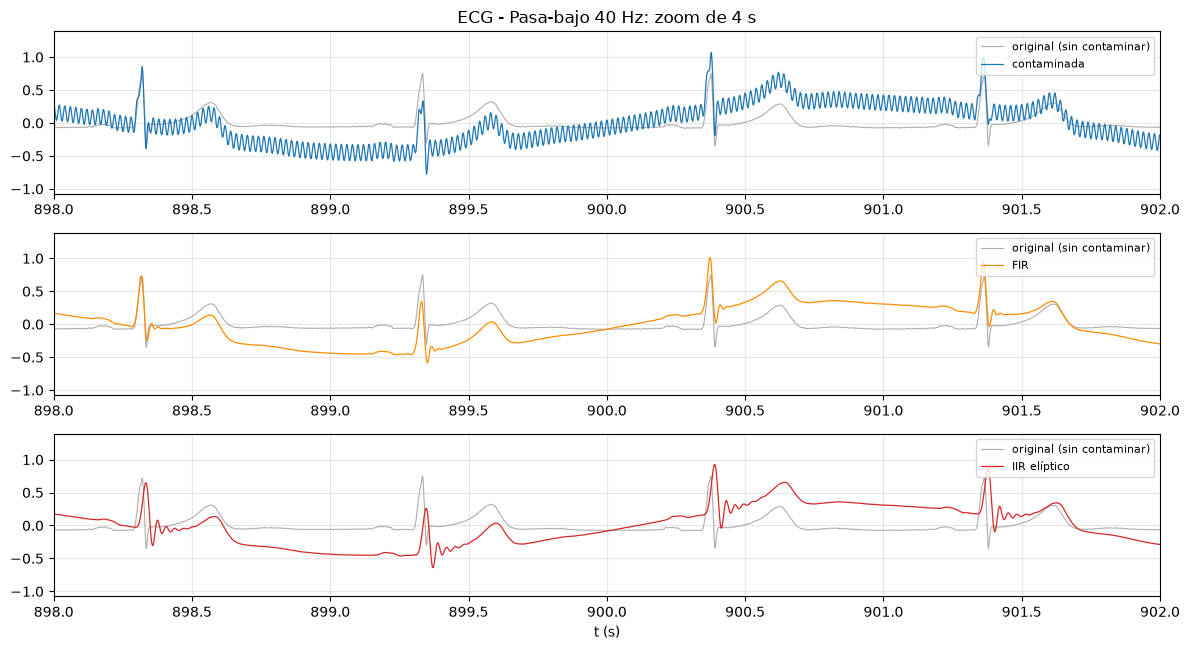

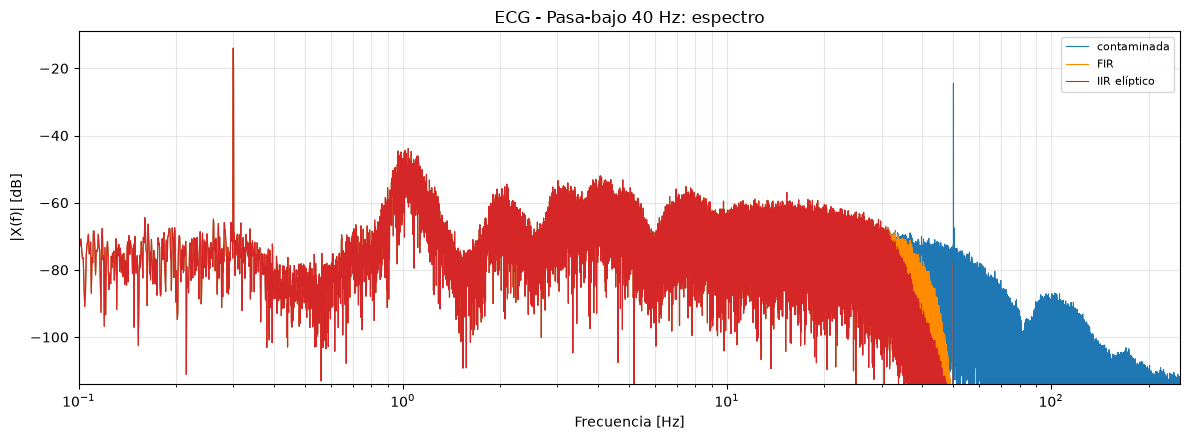

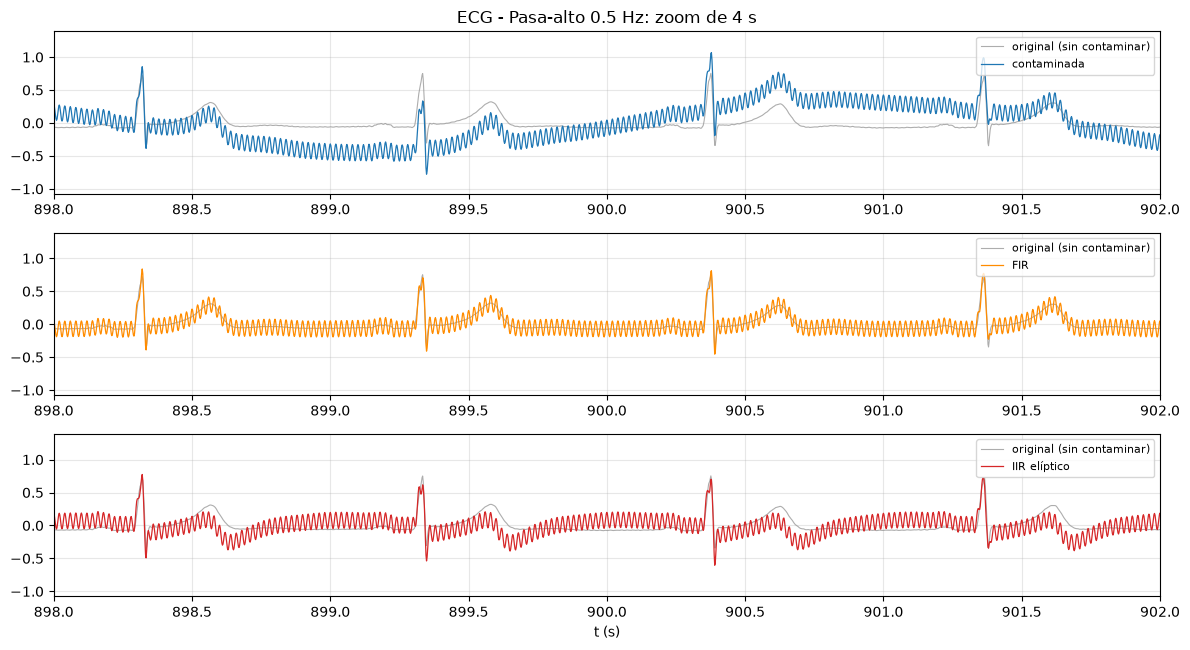

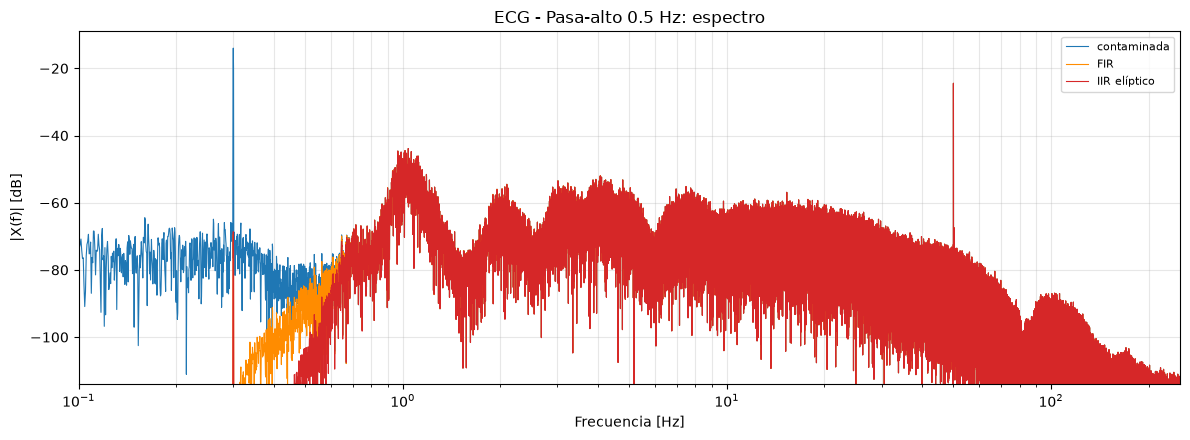

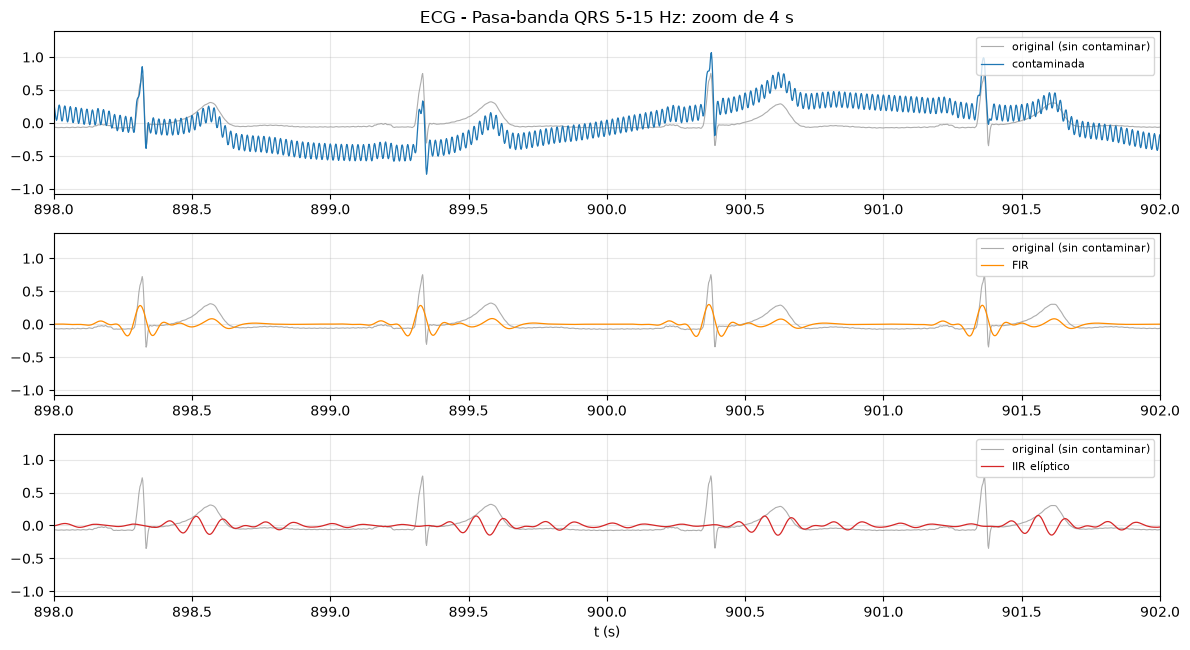

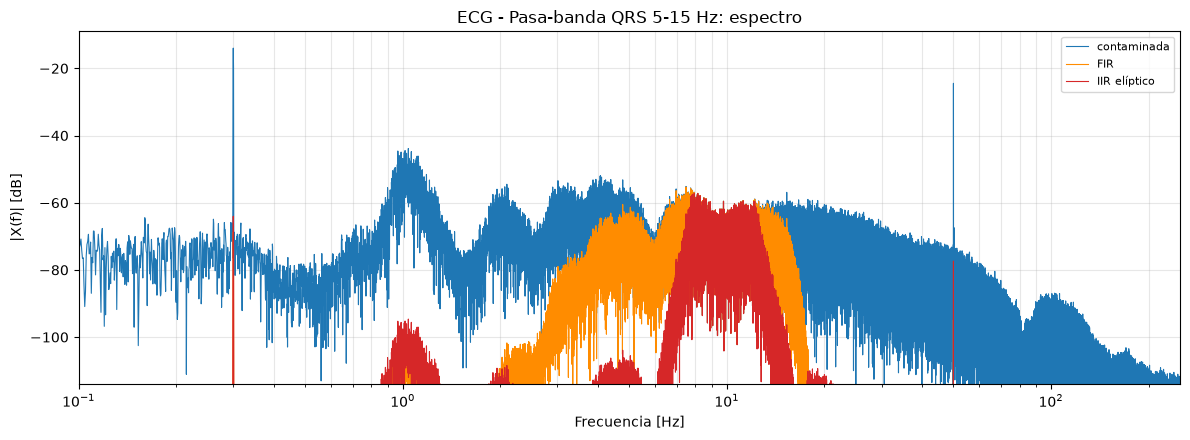

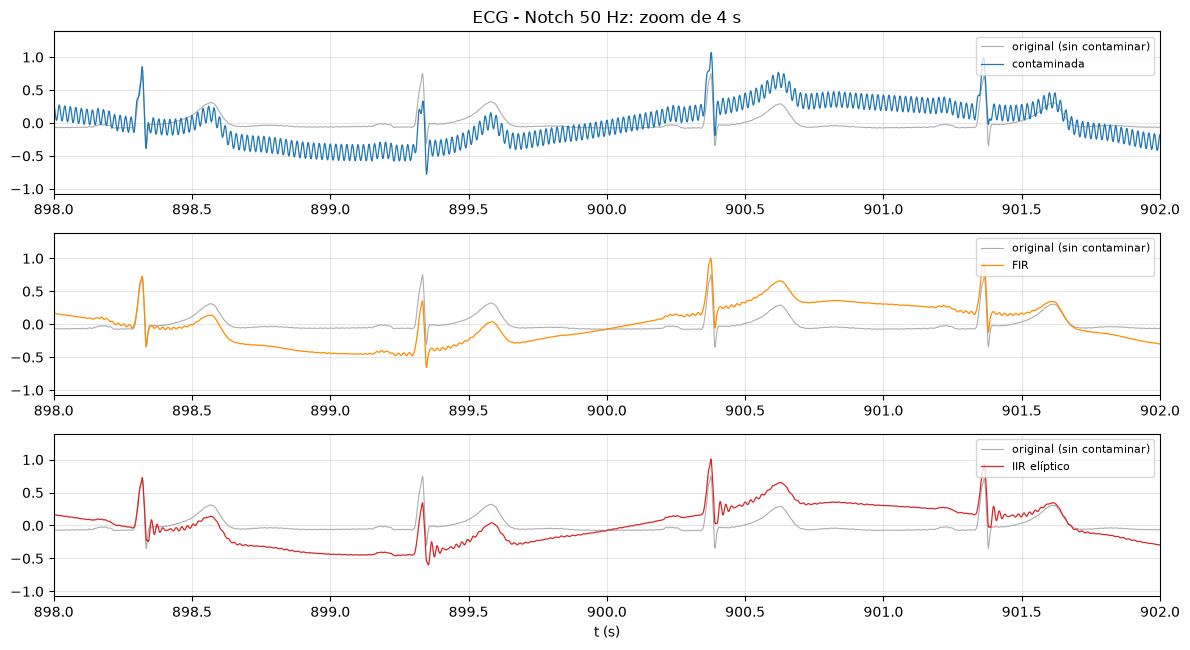

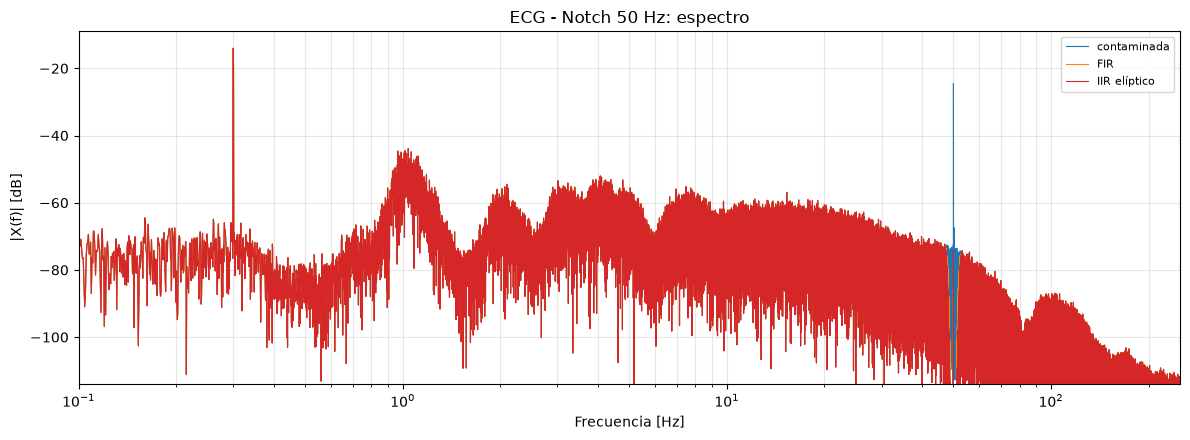

In [23]:
for nombre in ['Pasa-bajo 40 Hz', 'Pasa-alto 0.5 Hz', 'Pasa-banda QRS 5-15 Hz', 'Notch 50 Hz']:
    y = res_ecg[nombre]
    curvas = [('contaminada', ecg_cont, 'C0'), ('FIR', y['FIR'], 'darkorange'), ('IIR elíptico', y['IIR'], 'C3')]
    graficar_tiempo(t_e, curvas, f'ECG - {nombre}: zoom de 4 s', zoom=ZOOM, ref=ecg_d)
    graficar_espectro(fs_e, curvas, f'ECG - {nombre}: espectro', fmax=fs_e / 2, fmin=0.1, log=True)
    print(nombre); display(tabla_metricas(ecg_d, ecg_cont, y, fs_e, bandas_ecg, RECORTE_E))

### PCG 

#### Pasa-banda 25–400 Hz

             ΔP baja 0-15 Hz [dB]  ΔP útil 35-350 Hz [dB]  ΔP alta 450-1000 Hz [dB]  SNR vs original [dB]  correlación
contaminada                  0.00                    0.00                      0.00                -14.99         0.18
FIR                        -72.59                   -0.00                    -74.89                 -0.80         0.38
IIR                        -61.86                   -0.05                    -52.97                 -2.83        -0.08



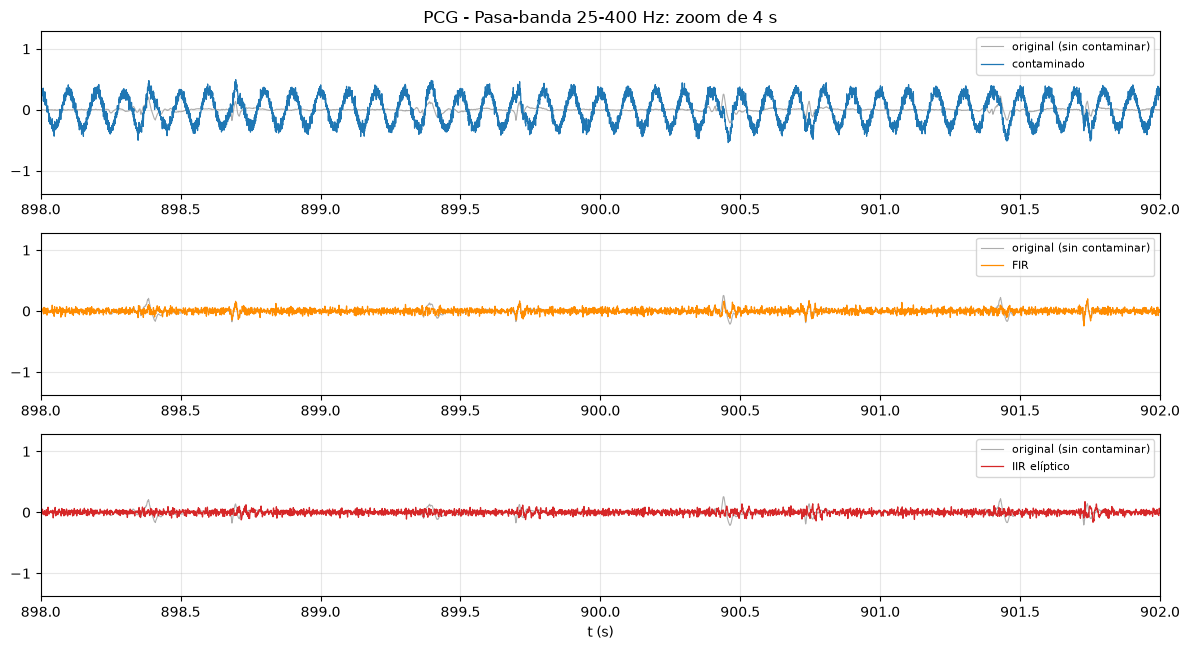

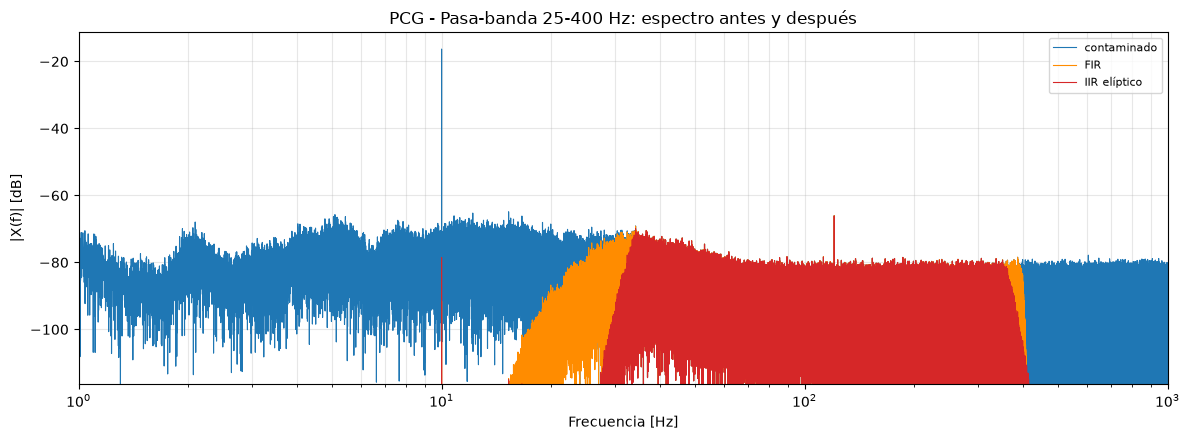

In [24]:
nombre = 'Pasa-banda 25-400 Hz'
y = res_pcg[nombre]
curvas = [('contaminado', pcg_cont, 'C0'), ('FIR', y['FIR'], 'darkorange'), ('IIR elíptico', y['IIR'], 'C3')]

graficar_tiempo(t_p, curvas, f'PCG - {nombre}: zoom de 4 s', zoom=ZOOM, ref=pcg_d)

graficar_espectro(fs_p, [(l, x, c) for l, x, c in curvas], f'PCG - {nombre}: espectro antes y después',
               fmax=fs_p / 2, fmin=1, log=True)

bandas_pcg = {'baja 0-15 Hz': (0, 15), 'útil 35-350 Hz': (35, 350), 'alta 450-1000 Hz': (450, 1000)}
display(tabla_metricas(pcg_d, pcg_cont, y, fs_p, bandas_pcg, RECORTE_P))

A continuación se grafica el espectograma de la señal. Es decir, la energía de la señal en función del tiempo (eje x) y la frecuencia (eje y), en dB. Se calcula con la FFT de ventanas cortas (256 muestras, con solapamiento) que se van deslizando sobre la señal.

El espectrograma permite ver cómo se distribuye la energía de S1 y S2 en el tiempo y la frecuencia, y que el filtro remueve las bandas sin información (la franja de 10 Hz abajo y el ruido arriba) sin tocar los sonidos cardíacos. Debajo se imprime cuánta potencia del PCG original en la banda de máxima energía de S1 (25–45 Hz, según el TP2) conserva el pasa-banda.

Pasa-banda 25-400 Hz | FIR: conserva el 83.4 % de la potencia del PCG en 25-45 Hz y el 33.5 % de la potencia total
Pasa-banda 25-400 Hz | IIR causal: conserva el 51.0 % de la potencia del PCG en 25-45 Hz y el 24.1 % de la potencia total


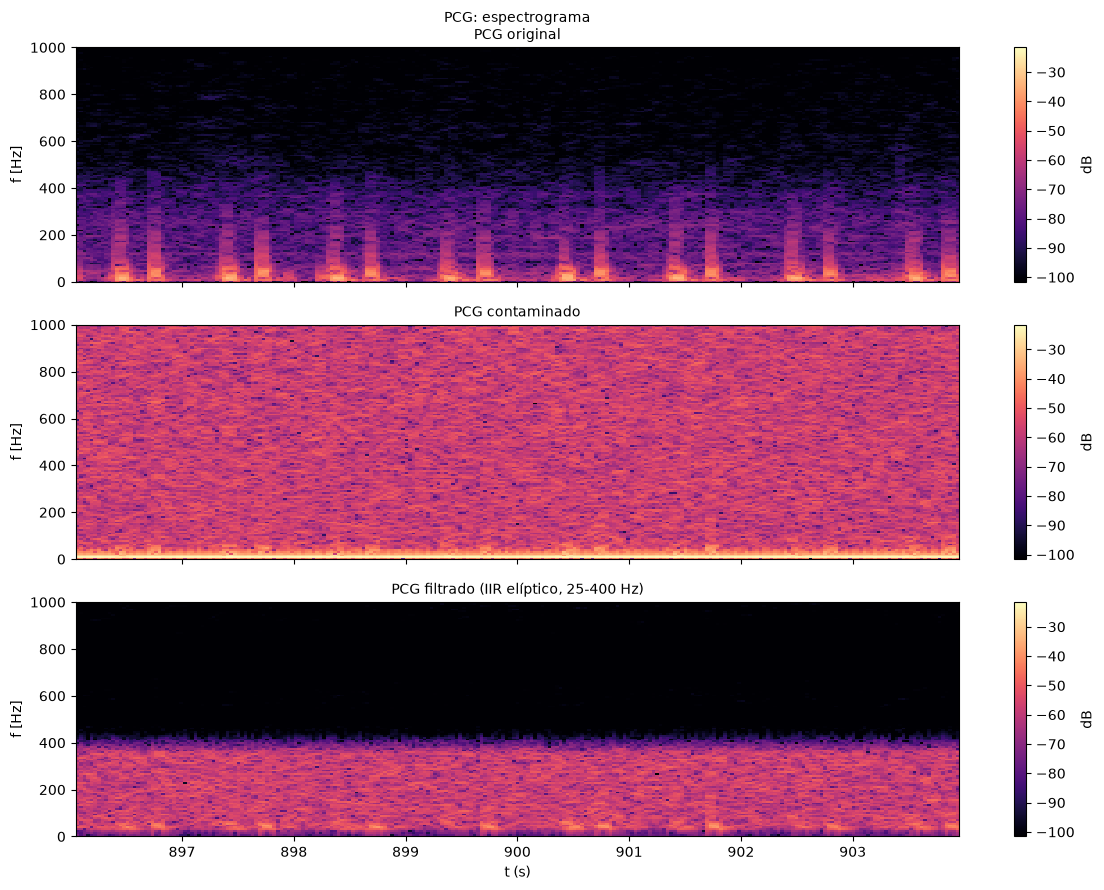

In [30]:
def graficar_espectrogramas(fs, curvas, titulo, fmax, t_lim=None):
    fig, axs = plt.subplots(len(curvas), 1, figsize=(12, 3 * len(curvas)), sharex=True)
    axs = np.atleast_1d(axs)
    S_all = []
    for label, x in curvas:
        if t_lim:
            x = x[int(t_lim[0] * fs):int(t_lim[1] * fs)]
            t0 = t_lim[0]
        else:
            t0 = 0
        f, t, S = signal.spectrogram(x, fs, nperseg=256, noverlap=192)
        S_all.append((label, f, t + t0, 10 * np.log10(S + 1e-20)))
    vmax = max(s.max() for _, _, _, s in S_all); vmin = vmax - 80
    for ax, (label, f, t, S) in zip(axs, S_all):
        im = ax.pcolormesh(t, f, S, shading='auto', vmin=vmin, vmax=vmax, cmap='magma')
        ax.set_ylim(0, fmax); ax.set_ylabel('f [Hz]'); ax.set_title(label, fontsize=10)
        fig.colorbar(im, ax=ax, label='dB')
    axs[0].set_title(f'{titulo}\n{S_all[0][0]}', fontsize=10)
    axs[-1].set_xlabel('t (s)')
    plt.tight_layout()
graficar_espectrogramas(fs_p, [('PCG original', pcg_d), ('PCG contaminado', pcg_cont),
                               ('PCG filtrado (IIR elíptico, 25-400 Hz)', y['IIR'])],
                        'PCG: espectrograma', fmax=1000, t_lim=(ZOOM[0] - 2, ZOOM[1] + 2))

# Cuánto de la banda de máxima energía de S1 (25-45 Hz) conserva el pasa-banda (filtrando solo el PCG original)
r = int(RECORTE_P * fs_p); sl = slice(r, -r)
for metodo, fn in filtros_de(dis_pcg, [nombre]).items():
    pcg_f = fn(pcg_d)
    print(f"{metodo}: conserva el {100 * potencia_banda(pcg_f[sl], fs_p, 25, 45) / potencia_banda(pcg_d[sl], fs_p, 25, 45):.1f} % "
          f"de la potencia del PCG en 25-45 Hz y el {100 * np.var(pcg_f[sl]) / np.var(pcg_d[sl]):.1f} % de la potencia total")

Vemos que **S1 y S2 siguen bien definidos en el tiempo:** las "manchas" verticales de cada sonido aparecen en los mismos instantes antes y después de filtrar (el retardo del IIR en la banda del PCG es de unos pocos ms, invisible a esta escala), y desaparecen la franja horizontal de 10 Hz y el piso de ruido por encima de ~450 Hz.

Sin embargo, el pasa-alto sí recorta parte de S1, dado que parte de la banda de 25–45 Hz cae en la transición. Lo impreso arriba cuantifica cuánta potencia de esa banda se conserva: 83 % con el FIR y 51 % con el IIR. Es el costo de poner la interferencia de 10 Hz en la banda de rechazo. Si se quisiera conservar más S1, se podría usar $f_p=25$, $f_{st}=12$ Hz (sigue rechazando 10 Hz), a cambio de un FIR de $1+3.32\cdot 2000/13\approx 513$ coeficientes en lugar de 333.

#### Pasa-bajo y pasa-alto por separado

Pasa-bajo 400 Hz
             ΔP baja 0-15 Hz [dB]  ΔP útil 35-350 Hz [dB]  ΔP alta 450-1000 Hz [dB]  SNR vs original [dB]  correlación
contaminada                   0.0                    0.00                      0.00                -14.99         0.18
FIR                           0.0                    0.01                    -63.28                -14.85         0.18
IIR                          -0.1                   -0.05                    -52.98                -14.76         0.17

Pasa-alto 25 Hz
             ΔP baja 0-15 Hz [dB]  ΔP útil 35-350 Hz [dB]  ΔP alta 450-1000 Hz [dB]  SNR vs original [dB]  correlación
contaminada                  0.00                    0.00                       0.0                -14.99         0.18
FIR                        -73.80                    0.00                       0.0                 -3.43         0.27
IIR                        -52.49                   -0.05                      -0.0                 -4.90        -0.08

Potencia rela

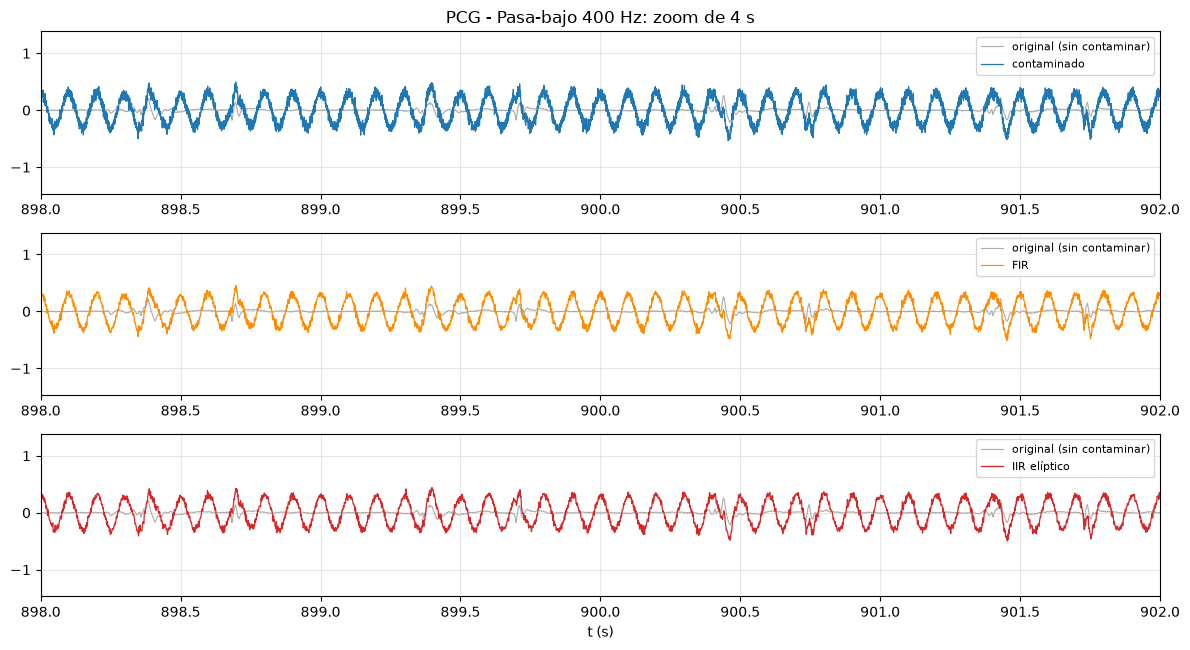

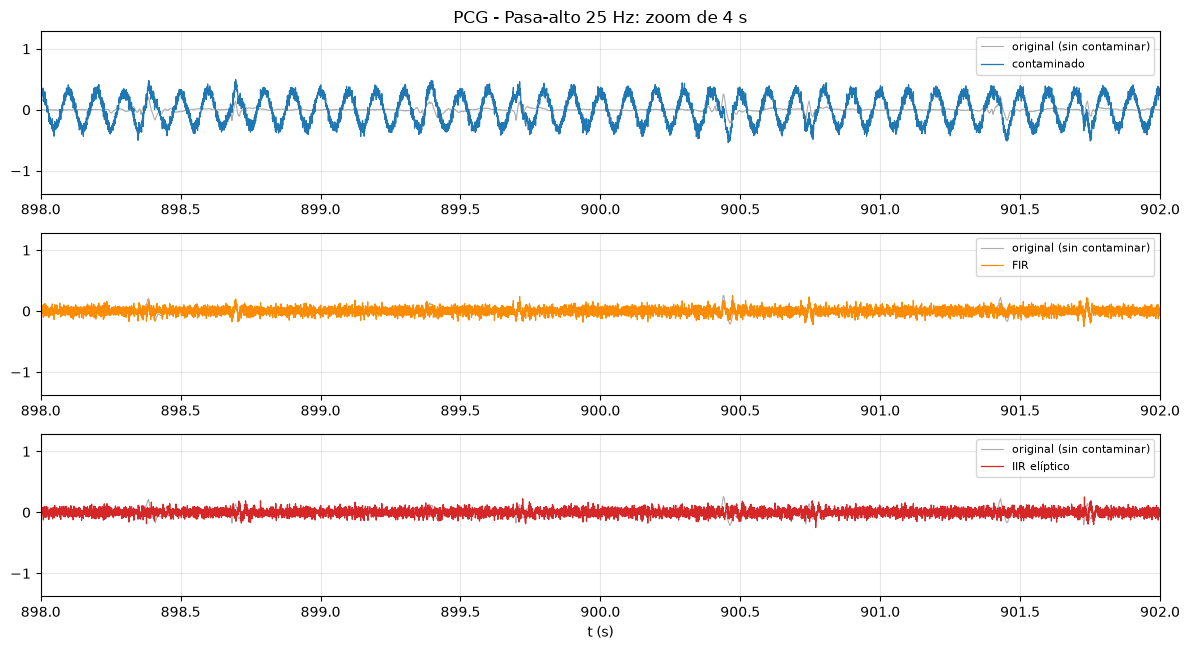

In [31]:
for nombre in ['Pasa-bajo 400 Hz', 'Pasa-alto 25 Hz']:
    y = res_pcg[nombre]
    graficar_tiempo(t_p, [('contaminado', pcg_cont, 'C0'), ('FIR', y['FIR'], 'darkorange'), ('IIR elíptico', y['IIR'], 'C3')],
                    f'PCG - {nombre}: zoom de 4 s', zoom=ZOOM, ref=pcg_d)
    print(nombre); display(tabla_metricas(pcg_d, pcg_cont, y, fs_p, bandas_pcg, RECORTE_P))

# Potencia de cada contaminación respecto de la del PCG (antes de filtrar)
P_pcg = np.var(pcg_d)
print(f"Potencia relativa al PCG: interferencia 10 Hz {10*np.log10(np.var(baja)/P_pcg):.1f} dB | ruido blanco {10*np.log10(np.var(blanco)/P_pcg):.1f} dB")

A partir de lo anterior vemos que el **pasa-alto** aporta más a la mejora de SNR: La interferencia de 10 Hz tiene una potencia de $0.045A^2$, 12.6 dB más que todo el ruido blanco ($0.0025A^2$; la diferencia también se ve en la línea impresa, que da ambas potencias relativas al PCG). El pasa-alto la elimina (−78 dB con el FIR, −52 dB con el IIR), mientras que el pasa-bajo solo puede sacar la parte del ruido que está por encima de 400 Hz: −4.1 dB, es decir, el 61 % de su potencia. Por eso, en la tabla de métricas, el pasa-bajo solo casi no mejora la SNR respecto de la señal contaminada, y el pasa-alto la mejora claramente, aunque también pierde la parte del PCG que está por debajo de 35 Hz.

Como las dos contaminaciones están en bandas distintas y el pasa-banda las ataca a la vez, el pasa-banda solo es mejor que cada uno por separado: elimina la interferencia de 10 Hz como el pasa-alto **y además** el ~60 % del ruido como el pasa-bajo. Su SNR es la mayor de los tres. Aun así queda acotada por el ruido que cae dentro de 25–400 Hz y por la parte de S1 que se pierde por debajo de 35 Hz.

Como límitación, sin embargo, vemos que el ruido blanco ocupa todas las frecuencias (también las de 25–400 Hz donde está el PCG), y ningún filtro de frecuencia puede separarlos dentro de esa banda. Lo mismo pasa con las ondas P, QRS y T del ECG, que se solapan en frecuencia: por eso el filtrado debe combinarse con información temporal (detección de picos R, ventanas, promediado de latidos). Esto también fue explorado enel trabajo anterior a partir del sumador y promediador.

## Conclusiones 

1. **FIR vs IIR para cada señal.** Todos los tipos de filtro, notch incluido, se pueden hacer con ambos. Con la misma plantilla ($r_p=0.1$ dB, $\alpha_s=50$ dB) lo que cambia es el costo, y depende de qué tan angosta es la transición respecto de $f_s$, porque $L_h\propto f_s/\Delta f$ y el orden del IIR depende de $f_{st}/f_p$.
   - **ECG:** el pasa-alto de 0.5 Hz y el notch son casos claros para el **IIR**: 4151 y 831 coeficientes de FIR (4.15 s y 0.83 s de retardo) contra órdenes 5 y 8 del elíptico (11 y 17 multiplicaciones por muestra), o incluso un `iirnotch` de orden 2. El costo es la fase no lineal.
   - **PCG:** las transiciones son relativamente anchas ($\Delta f/f_s$ = 0.01–0.05) y el **FIR** es comparable: 333 coeficientes (167 aprovechando la simetría) contra 25 multiplicaciones del elíptico pasa-banda, y 69 (35) contra 13 en el pasa-bajo. Con fase lineal y solo 83 ms de retardo, es la mejor opción si se quiere conservar la relación temporal entre S1, S2 y el ECG (lo cual es especialmente relevante dado que se trata de señales médicas)
   - **Familia de IIR:** con la plantilla común, el Butterworth necesita órdenes 10–42 y en forma $B(z)/A(z)$ se vuelve inestable o deja de cumplir la plantilla en 5 de los 8 filtros, solo por el redondeo de los coeficientes. Por eso se usa el **elíptico**, que cumple la misma plantilla con órdenes 5–12 y es estable en todos los casos (el pasa-banda del ECG, en dos etapas $(b,a)$).
2. **Fase.** El FIR retrasa todo $(L_h-1)/2$ muestras: se compensa y la salida queda alineada (`mode='same'`). El IIR retrasa cada frecuencia distinto: ~22 ms el QRS y ~0.44 s la banda de 1 Hz en el pasa-banda del ECG. Desplaza y deforma las ondas, y por eso su SNR contra el original es la peor, aunque atenúe las interferencias igual que el FIR. La fase **importa** cuando se miden tiempos o formas: detección de picos R, intervalo RR, segmento S-T, y la relación temporal entre el ECG y el PCG. Sin embargo, no es tan importante en la detección de anomalías como soplos, o cuando solo interesa la energía por banda.
3. **Trade-offs.**
   - **Orden vs selectividad:** en el FIR, el ancho de transición baja como $1/L_h$ pero los lóbulos no bajan. En el Butterworth, cada orden suma selectividad pero también retardo de grupo (de 5.5 a 20 ms entre los órdenes 2 y 8) y, en forma $B(z)/A(z)$, sensibilidad al redondeo de los coeficientes.
   - **Ancho de transición vs atenuación (ventanas):** de la rectangular a Blackman, la atenuación pasa de 21 a 75 dB y $C$ de 1.84 a 11.1, como predice la tabla.
   - **Selectividad vs rizado y fase (familias IIR):** con orden 4, el elíptico atenúa 19.6 dB en 50 Hz contra 8.8 dB del Butterworth, pero tiene rizado y casi el triple de retardo de grupo _máximo_.
   - **Recortar banda vs quitar solo la interferencia:** el pasa-banda resuelve la deriva y la red a la vez pero se lleva todo lo que está por encima de 40 Hz; el notch conserva 40–250 Hz y quita solo la red, pero no resuelve la deriva.
4. **Limitaciones.** El ruido que cae dentro de la banda de la señal no se puede filtrar: con el pasa-banda del PCG queda el 37 % del ruido (casi todo dentro de 25–400 Hz), en el límite del filtro ideal. Las ondas del ECG (P, QRS, T) y los sonidos del PCG (S1, S2) se solapan en frecuencia, así que ningún filtro las separa: hace falta información temporal. Además, los IIR con polos muy cerca de $z=1$ tienen transitorios de varios segundos.